# EuroSAT-RGB: Leakage-Controlled Classification and Quantitative XAI
## Lean 8-stage research notebook (revised)

Workflow: (1) dataset audit, (2) leakage control and splitting, (3) model development,
(4) predictive evaluation, (5) XAI generation, (6) quantitative XAI evaluation,
(7) robustness/statistics, and (8) reporting.

**Scope:** RGB JPEG images only. This notebook does not establish geographic independence unless authoritative geographic/source metadata is supplied and used for grouping. pHash similarity is a candidate signal, not proof of duplicate scenes. Do not remove images automatically based on pHash.

### Revision log (what changed and why)

| Stage | Change | Reason |
|---|---|---|
| 0 | Full seeding (Python, NumPy, PyTorch, cuDNN); `RESULTS` registry | Original seeded only Python/NumPy, so training was not reproducible |
| 1 | Non-image files separated from the manifest; images fully decoded (`load()`), not only `verify()`; resumable checkpoints write to a *partial* file and never overwrite the cache; dimension/mode checks restricted to valid images; exact-duplicate groups report label conflicts | Original checkpoint overwrite discarded cached hashes on interruption; `verify()` misses truncated JPEGs; error rows inflated the dimension count |
| 2 | Exact SHA-256 duplicates are now merged into duplicate groups automatically; manual-review gate enforced; iterative union-find; split verified for path/group disjointness, coverage, and per-class share; contact sheets, pair-metrics triage and `apply_decisions` for the manual review; a freeze guard refuses to replace an existing, different test split | Original grouped only manually confirmed pairs, so byte-identical files could cross partitions |
| 3 | Per-run seeding and loader generator; rotation/flip augmentation appropriate to nadir imagery; cosine schedule, AMP, early stopping; sample-weighted losses; CPU-side best-state copy; seed-tagged checkpoints and a loader | Original used 10° rotation (black corners, no vertical flip), unweighted batch means, no determinism |
| 4 | Temperature scaling fitted on validation only; ECE; saved predictions, per-class report, confusion matrix; test evaluation gated by an explicit flag | "Calibration" was announced but not implemented; predictions were not persisted for later stages |
| 5 | Explicit target class (`ClassifierOutputTarget`); EfficientNet support; Integrated Gradients; class-balanced correct/incorrect sampling | Original relied on the implicit top-1 target, supported ResNet only, and had no sampling protocol |
| 6 | Vectorised deletion **and insertion**, AUCs, most/least/random controls, paired Wilcoxon; transformation-stability and cascading parameter-randomisation checks | Original provided one slow deletion function with no controls, insertion, AUC, stability, or sanity check |
| 7 | Group-aware bootstrap, exact McNemar with Holm correction, label-preserving perturbation suite with paired tests | Original had imports and comments only for McNemar/Wilcoxon |
| 8 | 600-dpi PNG and vector-PDF manuscript figures, mean ± SD results tables, an automated 19-check validity audit, and a manifest with environment versions, hyper-parameters, file hashes, review status and results | Original produced no figures or tables and its manifest could not support replication |

## Stage 0 — Configuration

In [1]:
from pathlib import Path
import os, io, json, random, hashlib, time, platform, sys, copy, itertools
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

SEED = 42

def seed_everything(seed):
    """Seed every RNG that influences training and evaluation."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except ImportError:
        pass

seed_everything(SEED)

DATASET_DIR = Path(r"D:\datasets\EuroSAT-RGB")
PROJECT_DIR = Path(r"C:\Users\DSAI\Desktop\EuroSAT_XAI_Research\newstudy")
AUDIT_DIR = PROJECT_DIR / "data" / "audit"
SPLIT_DIR = PROJECT_DIR / "splits"
OUTPUT_DIR = PROJECT_DIR / "outputs"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
for d in [AUDIT_DIR, SPLIT_DIR, OUTPUT_DIR, CHECKPOINT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Master run switch. True: Run All executes every stage, in order, unattended.
# False: each stage's own RUN_* flag below defaults to False, so stages run one at a time.
RUN_ALL = True

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
EXPECTED_SIZE = 64          # EuroSAT patches are 64 x 64 px
RESULTS = {}                # collected metrics, written to the reproducibility manifest in Stage 8

# ---- Publication figure settings: 600 dpi, embedded TrueType fonts, journal column widths, readable type sizes
import re
import matplotlib as mpl

FIG_DPI = 600
FIG_FORMATS = ("png", "pdf")    # PNG at 600 dpi plus a vector PDF; add "tiff" if the target journal requires it
FIG_W1, FIG_W2 = 3.5, 7.2       # single- and double-column widths in inches
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
OKABE_ITO = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#CC79A7", "#F0E442", "#000000"]  # colour-blind safe
MODEL_LABEL = {"resnet18": "ResNet-18", "efficientnet_b0": "EfficientNet-B0"}
METHOD_LABEL = {"gradcam": "Grad-CAM", "ig": "Integrated Gradients"}

mpl.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": FIG_DPI, "savefig.bbox": "tight", "savefig.pad_inches": 0.04,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9.5, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.fontsize": 8.5, "figure.titlesize": 10.5,
    "axes.linewidth": 0.8, "lines.linewidth": 1.5, "lines.markersize": 4.5,
    "xtick.major.width": 0.8, "ytick.major.width": 0.8, "xtick.major.size": 3.5, "ytick.major.size": 3.5,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,          # embed TrueType fonts (editable and accepted by publishers)
})

def pretty_class(name):
    """'HerbaceousVegetation' -> 'Herbaceous Vegetation'."""
    return re.sub(r"(?<=[a-z])(?=[A-Z])", " ", name)

def save_figure(fig, name, directory=None, formats=None):
    """Save one figure in every requested format at FIG_DPI; returns the written paths."""
    directory = Path(directory or FIG_DIR)
    directory.mkdir(parents=True, exist_ok=True)
    out = []
    for ext in (formats or FIG_FORMATS):
        kw = {"dpi": FIG_DPI}
        if ext == "tiff":
            kw["pil_kwargs"] = {"compression": "tiff_lzw"}
        path = directory / f"{name}.{ext}"
        fig.savefig(path, **kw)
        out.append(path)
    return out

print("Python:", platform.python_version())
print("Dataset exists:", DATASET_DIR.is_dir())

Python: 3.11.18
Dataset exists: True


## Stage 1 — Dataset audit and quality control

Creates a manifest, validates image readability and dimensions, and computes exact SHA-256 hashes. Both the integrity audit and the hashing use resumable CSV caches. Progress is written to a separate `.partial.csv` file, so an interrupted run can resume without destroying previously cached results.

In [2]:
# 1A. Inventory (non-image files are listed separately and never enter the manifest)
if not DATASET_DIR.is_dir():
    raise FileNotFoundError(DATASET_DIR)

rows, skipped = [], []
for class_dir in sorted(p for p in DATASET_DIR.iterdir() if p.is_dir()):
    for fp in sorted(class_dir.rglob("*")):
        if not fp.is_file():
            continue
        rel = fp.relative_to(DATASET_DIR).as_posix()
        if fp.suffix.lower() in IMAGE_EXTS:
            rows.append({"relative_path": rel, "class_name": class_dir.name})
        else:
            skipped.append(rel)

manifest = pd.DataFrame(rows)
manifest.to_csv(AUDIT_DIR / "dataset_manifest.csv", index=False)
pd.Series(skipped, name="relative_path", dtype=str).to_csv(AUDIT_DIR / "non_image_files.csv", index=False)
print("Images:", len(manifest), "| non-image files skipped:", len(skipped))
display(manifest.groupby("class_name").size().rename("count").to_frame())
if manifest.class_name.nunique() != 10:
    print("WARNING: EuroSAT has 10 classes; found", manifest.class_name.nunique())

Images: 27000 | non-image files skipped: 0


,count
class_name,
AnnualCrop,3000
Forest,3000
HerbaceousVegetation,3000
Highway,2500
Industrial,2500
Pasture,2000
PermanentCrop,2500
Residential,3000
River,2500


In [3]:
# 1B. Integrity audit with resumable CSV checkpoints
def load_csv_cache(paths, required):
    """Merge cached rows keyed by relative_path; later paths override earlier ones."""
    cache = {}
    for p in paths:
        if Path(p).exists():
            df = pd.read_csv(p)
            if required.issubset(df.columns) and "relative_path" in df.columns:
                cache.update(df.set_index("relative_path").to_dict("index"))
    return cache

integrity_path = AUDIT_DIR / "image_integrity_report.csv"
integrity_partial = AUDIT_DIR / "image_integrity_report.partial.csv"
cache = load_csv_cache([integrity_path, integrity_partial],
                       {"class_name", "file_size", "modified_ns", "status"})

audit = []
for i, r in enumerate(manifest.itertuples(index=False), 1):
    fp = DATASET_DIR / r.relative_path
    st = fp.stat()
    prev = cache.get(r.relative_path)
    if (prev is not None and int(prev["file_size"]) == st.st_size
            and int(prev["modified_ns"]) == st.st_mtime_ns):
        item = {"relative_path": r.relative_path, **prev}
    else:
        item = dict(relative_path=r.relative_path, class_name=r.class_name,
                    file_size=st.st_size, modified_ns=st.st_mtime_ns,
                    width=None, height=None, image_format=None, image_mode=None,
                    image_bands=None, status="error", error_message=None)
        try:
            with Image.open(fp) as im:
                im.verify()                      # structural check
            with Image.open(fp) as im:
                im.load()                        # full decode catches truncated data
                item.update(width=im.width, height=im.height, image_format=im.format,
                            image_mode=im.mode, image_bands=str(im.getbands()),
                            status="valid")
        except Exception as e:
            item["error_message"] = repr(e)
    audit.append(item)
    if i % 2000 == 0:
        pd.DataFrame(audit).to_csv(integrity_partial, index=False)
        print(f"Audited {i:,}/{len(manifest):,}")

integrity = pd.DataFrame(audit)
integrity.to_csv(integrity_path, index=False)
integrity_partial.unlink(missing_ok=True)

is_valid = integrity.status.eq("valid")
print(integrity.status.value_counts())
print("Valid images with unexpected dimensions:",
      int((is_valid & ((integrity.width != EXPECTED_SIZE) | (integrity.height != EXPECTED_SIZE))).sum()))
print("Valid images not in RGB mode:", int((is_valid & integrity.image_mode.ne("RGB")).sum()))

Audited 2,000/27,000
Audited 4,000/27,000
Audited 6,000/27,000
Audited 8,000/27,000
Audited 10,000/27,000
Audited 12,000/27,000
Audited 14,000/27,000
Audited 16,000/27,000
Audited 18,000/27,000
Audited 20,000/27,000
Audited 22,000/27,000
Audited 24,000/27,000
Audited 26,000/27,000
status
valid    27000
Name: count, dtype: int64
Valid images with unexpected dimensions: 0
Valid images not in RGB mode: 0


In [4]:
# 1C. Exact byte-duplicate detection with a resumable CSV cache
HASH_CSV = AUDIT_DIR / "stage_1_exact_hashes.csv"
HASH_PARTIAL = AUDIT_DIR / "stage_1_exact_hashes.partial.csv"

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

hash_cache = load_csv_cache([HASH_CSV, HASH_PARTIAL],
                            {"class_name", "file_size", "modified_ns", "sha256", "status"})
valid_rows = integrity.loc[integrity.status.eq("valid")]

hash_rows = []
for i, r in enumerate(valid_rows.itertuples(index=False), start=1):
    prev = hash_cache.get(r.relative_path)
    base = {"relative_path": r.relative_path, "class_name": r.class_name,
            "file_size": int(r.file_size), "modified_ns": int(r.modified_ns)}
    if (prev is not None and str(prev["status"]) == "valid" and pd.notna(prev["sha256"])
            and int(prev["file_size"]) == base["file_size"]
            and int(prev["modified_ns"]) == base["modified_ns"]):
        item = {**base, "sha256": str(prev["sha256"]), "status": "valid", "error": None}
    else:
        try:
            item = {**base, "sha256": sha256_file(DATASET_DIR / r.relative_path),
                    "status": "valid", "error": None}
        except Exception as e:
            item = {**base, "sha256": None, "status": "error", "error": repr(e)}
    hash_rows.append(item)
    if i % 2000 == 0:
        pd.DataFrame(hash_rows).to_csv(HASH_PARTIAL, index=False)
        print(f"Hashed {i:,}/{len(valid_rows):,} valid images")

hashes = pd.DataFrame(hash_rows)
hashes.to_csv(HASH_CSV, index=False)
HASH_PARTIAL.unlink(missing_ok=True)

exact = hashes.loc[hashes.status.eq("valid") & hashes.sha256.notna()]
exact_groups = (exact.groupby("sha256")
                .agg(count=("relative_path", "size"),
                     n_classes=("class_name", "nunique"),
                     files=("relative_path", lambda x: " | ".join(sorted(x))),
                     classes=("class_name", lambda x: " | ".join(sorted(set(x)))))
                .reset_index())
exact_groups = exact_groups.loc[exact_groups["count"] > 1].copy()
exact_groups.to_csv(AUDIT_DIR / "stage_1_exact_duplicate_groups.csv", index=False)

print("Hash rows:", len(hashes), "| hash errors:", int(hashes.status.ne("valid").sum()))
print("Exact duplicate groups:", len(exact_groups))
print("Redundant exact copies:", int((exact_groups["count"] - 1).sum()) if len(exact_groups) else 0)
print("Exact-duplicate groups spanning more than one class (label conflicts):",
      int(exact_groups.n_classes.gt(1).sum()) if len(exact_groups) else 0)

Hashed 2,000/27,000 valid images
Hashed 4,000/27,000 valid images
Hashed 6,000/27,000 valid images
Hashed 8,000/27,000 valid images
Hashed 10,000/27,000 valid images
Hashed 12,000/27,000 valid images
Hashed 14,000/27,000 valid images
Hashed 16,000/27,000 valid images
Hashed 18,000/27,000 valid images
Hashed 20,000/27,000 valid images
Hashed 22,000/27,000 valid images
Hashed 24,000/27,000 valid images
Hashed 26,000/27,000 valid images
Hash rows: 27000 | hash errors: 0
Exact duplicate groups: 0
Redundant exact copies: 0
Exact-duplicate groups spanning more than one class (label conflicts): 0


**Stage 1 decision gate:** resolve corrupt/missing files, exact duplicates, and any label conflicts before splitting. An earlier completed audit reported 27,000 valid 64×64 RGB images and zero exact SHA-256 duplicate groups; this notebook rechecks the current source. Exact duplicates, if any are found, are merged into duplicate groups automatically in Stage 2.

## Stage 2 — Leakage prevention, metadata assessment, and split

Byte-identical files and manually confirmed near-duplicate pairs are merged into connected components, and each component is kept within a single partition. pHash candidates are never grouped automatically. Spatially independent evaluation requires defensible geographic/source identifiers; the ordinary class-folder JPEG collection does not provide them.

In [5]:
# 2A. Load the completed review sheet, if available, and enforce the review gate
REQUIRE_COMPLETE_REVIEW = True   # raise if the sheet contains undecided rows
# Setting this False is a documented methodological compromise: undecided pairs are treated as
# NOT duplicates, so possible near-duplicate leakage remains. The choice is recorded in the manifest.

APPLY_EMBEDDED_REVIEW = True    # pre-fills EMPTY rows only, from an assistant visual triage (provenance: review_source)
AUTHOR_REVIEW_CONFIRMED = False # set True only after YOU have inspected the original images and accepted the sheet
# Decision vocabulary: duplicate | uncertain | not_duplicate. 'uncertain' is grouped like 'duplicate' (conservative),
# so uncertainty is never silently converted into a negative decision. Until AUTHOR_REVIEW_CONFIRMED is True, the
# validity audit reports the review as WARN, and the manuscript must not describe it as a completed manual review.
# Decisions from the visual review of the 142 pHash candidates (contact sheets pages 1-36).
# They are applied ONLY to a sheet that matches the reviewed one exactly (142 rows and identical file names for the
# pairs below), and only to rows that are still undecided, so decisions you record yourself are never overwritten.
EMBEDDED_DUPLICATES = {
    "PAIR_0021": ("Highway/Highway_291.jpg", "Highway/Highway_513.jpg", "Same interchange and buildings; near-identical scene."),
    "PAIR_0027": ("River/River_492.jpg", "River/River_597.jpg", "Same river bend and beach; near-identical scene."),
}
EMBEDDED_PROVISIONAL = {      # uncertain pairs, grouped conservatively to rule out leakage; confirm on full-size images
    "PAIR_0039": ("SeaLake/SeaLake_2018.jpg", "SeaLake/SeaLake_427.jpg", "shared speck cluster, different tint"),
    "PAIR_0044": ("SeaLake/SeaLake_2266.jpg", "SeaLake/SeaLake_2539.jpg", "same navy water, teal patch top-right"),
    "PAIR_0110": ("SeaLake/SeaLake_1166.jpg", "SeaLake/SeaLake_2266.jpg", "similar navy water and top-right features"),
    "PAIR_0115": ("SeaLake/SeaLake_1335.jpg", "SeaLake/SeaLake_58.jpg", "bright feature top-right, different tint"),
    "PAIR_0117": ("SeaLake/SeaLake_1593.jpg", "SeaLake/SeaLake_2156.jpg", "green wedge bottom-left, similar water"),
}
EMBEDDED_SHEET_ROWS = 142

def apply_embedded_review(path):
    sheet = pd.read_csv(path, dtype={"review_decision": "string", "review_notes": "string"})
    if "review_notes" not in sheet.columns:
        sheet["review_notes"] = pd.Series([pd.NA] * len(sheet), dtype="string")
    if "review_source" not in sheet.columns:
        sheet["review_source"] = pd.Series([pd.NA] * len(sheet), dtype="string")
    sheet["review_source"] = sheet["review_source"].astype("string")
    expected = {**EMBEDDED_DUPLICATES, **EMBEDDED_PROVISIONAL}
    if "pair_id" not in sheet.columns or len(sheet) != EMBEDDED_SHEET_ROWS or not sheet.pair_id.is_unique:
        return {"applied": False, "reason": "sheet is not the reviewed 142-row sheet"}
    by_id = sheet.set_index("pair_id")
    for pid, (a, b, _) in expected.items():
        if pid not in by_id.index or (by_id.loc[pid, "image_1"], by_id.loc[pid, "image_2"]) != (a, b):
            return {"applied": False, "reason": f"{pid} does not match the reviewed pair"}
    empty = sheet.review_decision.fillna("").str.strip().eq("")
    for i in sheet.index[empty]:
        pid = sheet.at[i, "pair_id"]
        sheet.at[i, "review_source"] = "assistant_prefill"
        if pid in EMBEDDED_DUPLICATES:
            sheet.at[i, "review_decision"], sheet.at[i, "review_notes"] = "duplicate", EMBEDDED_DUPLICATES[pid][2]
        elif pid in EMBEDDED_PROVISIONAL:
            sheet.at[i, "review_decision"] = "uncertain"
            sheet.at[i, "review_notes"] = "UNCERTAIN, grouped conservatively; author to confirm. " + EMBEDDED_PROVISIONAL[pid][2]
        else:
            sheet.at[i, "review_decision"] = "not_duplicate"
            same = sheet.at[i, "comparison_type"] == "within_class" if "comparison_type" in sheet.columns else False
            sheet.at[i, "review_notes"] = ("Visually distinct scenes." if same
                                           else "pHash collision on low-texture tiles; different scenes.")
    sheet.to_csv(path, index=False)
    # worklist for the author: pre-filled rows ordered by how much scrutiny they deserve
    order = {"duplicate": 0, "uncertain": 0, "not_duplicate": 1}
    wl = sheet[sheet.review_source.eq("assistant_prefill")].copy()
    wl["_p"] = [order[d] * 2 + (0 if t == "within_class" else 1) for d, t in zip(wl.review_decision, wl.get("comparison_type", "within_class"))]
    wl.sort_values(["_p", "hamming_distance"]).drop(columns="_p").to_csv(Path(path).with_name("author_review_worklist.csv"), index=False)
    return {"applied": True, "rows_filled": int(empty.sum()), "confirmed_duplicates": sorted(EMBEDDED_DUPLICATES),
            "uncertain_pairs": sorted(EMBEDDED_PROVISIONAL),
            "status": "assistant pre-fill from contact-sheet triage; author confirmation required"}

candidates = [AUDIT_DIR / "stage_1_4_visual_review" / "near_duplicate_review_sheet.csv",
              AUDIT_DIR / "near_duplicate_review_sheet.csv"]
REVIEW_CSV = next((c for c in candidates if c.exists()), None)
embedded_summary = {"applied": False, "reason": "disabled or no sheet"}
if REVIEW_CSV and APPLY_EMBEDDED_REVIEW:
    embedded_summary = apply_embedded_review(REVIEW_CSV)
    print("Embedded review decisions:", embedded_summary)
review = pd.read_csv(REVIEW_CSV) if REVIEW_CSV else pd.DataFrame()
manual_review_status = {"sheet_found": REVIEW_CSV is not None, "rows": int(len(review)),
                        "undecided": None, "path": str(REVIEW_CSV) if REVIEW_CSV else None,
                        "incomplete_review_override": not REQUIRE_COMPLETE_REVIEW,
                        "embedded_decisions": embedded_summary}

if len(review):
    missing = {"image_1", "image_2", "review_decision"} - set(review.columns)
    if missing:
        raise ValueError(f"Review sheet lacks required columns: {sorted(missing)}")
    decisions = review.review_decision.astype("string").fillna("").str.strip().str.lower()
    unknown = sorted(set(decisions[decisions != ""]) - {"duplicate", "uncertain", "not_duplicate"})
    if unknown:
        raise ValueError(f"Unknown review_decision values {unknown}; use duplicate, uncertain or not_duplicate.")
    src = review["review_source"].astype("string").fillna("") if "review_source" in review.columns else pd.Series([""] * len(review))
    manual_review_status["prefilled_rows"] = int(src.eq("assistant_prefill").sum())
    manual_review_status["uncertain_rows"] = int(decisions.eq("uncertain").sum())
    manual_review_status["author_confirmed"] = bool(AUTHOR_REVIEW_CONFIRMED)
    print("Review rows:", len(review))
    print(decisions.replace("", "<undecided>").value_counts())
    manual_review_status["undecided"] = int(decisions.eq("").sum())
    if REQUIRE_COMPLETE_REVIEW and manual_review_status["undecided"]:
        raise RuntimeError(f"{manual_review_status['undecided']} review rows are undecided. "
                           "Complete the manual review before constructing splits.")
    print("Rows labelled 'duplicate' or 'uncertain' are merged into one group; only 'not_duplicate' keeps pairs separable.")
    if manual_review_status["prefilled_rows"] and not AUTHOR_REVIEW_CONFIRMED:
        print(f"NOTE: {manual_review_status['prefilled_rows']} decisions are an assistant pre-fill (see author_review_worklist.csv). "
              "Verify them on the original images, then set AUTHOR_REVIEW_CONFIRMED = True.")
else:
    print("No review sheet found: near-duplicate leakage has NOT been controlled beyond exact hashes.")

# Optional authoritative metadata file; set this only if you possess one.
METADATA_CSV = None  # Example: Path(r"D:\datasets\EuroSAT\metadata.csv")
if METADATA_CSV is not None:
    metadata = pd.read_csv(METADATA_CSV)
    display(metadata.head())
    print("Metadata fields:", metadata.columns.tolist())
else:
    print("No geographic metadata supplied: spatial independence is NOT established.")

Embedded review decisions: {'applied': True, 'rows_filled': 0, 'confirmed_duplicates': ['PAIR_0021', 'PAIR_0027'], 'uncertain_pairs': ['PAIR_0039', 'PAIR_0044', 'PAIR_0110', 'PAIR_0115', 'PAIR_0117'], 'status': 'assistant pre-fill from contact-sheet triage; author confirmation required'}
Review rows: 142
review_decision
not_duplicate    135
duplicate          7
Name: count, dtype: Int64
Rows labelled 'duplicate' or 'uncertain' are merged into one group; only 'not_duplicate' keeps pairs separable.
No geographic metadata supplied: spatial independence is NOT established.


**Completing the manual review.** Run the next cell to render the candidate pairs as numbered contact sheets
(upsampled for visibility), inspect them, then record a decision for every row, either by editing
`review_decision` in the CSV (values `duplicate`, `uncertain` or `not_duplicate`; `uncertain` is grouped like `duplicate`) or with `apply_decisions`. Decisions must come
from your own visual judgement; the helper deliberately offers no bulk-labelling shortcut.

In [6]:
SHOW_REVIEW_SHEETS = False      # True to render the contact sheets inline (they are optional once decisions are embedded)
PAIRS_PER_PAGE = 12
review_sheet_dir = AUDIT_DIR / "review_contact_sheets"

def render_review_sheets(rev, per_page=PAIRS_PER_PAGE, show=True):
    review_sheet_dir.mkdir(parents=True, exist_ok=True)
    extra = [c for c in rev.columns if any(k in c.lower() for k in ("dist", "hamming", "phash", "sim"))]
    cols = 2                                    # pairs per row
    for page, start in enumerate(range(0, len(rev), per_page), 1):
        chunk = rev.iloc[start:start + per_page]
        nrows = -(-len(chunk) // cols)
        fig, axes = plt.subplots(nrows, cols * 2, figsize=(4 * cols * 1.6, 2.1 * nrows), squeeze=False)
        for ax in axes.ravel():
            ax.axis("off")
        for k, (idx, r) in enumerate(chunk.iterrows()):
            row, c0 = divmod(k, cols)
            for j, key in enumerate(("image_1", "image_2")):
                with Image.open(DATASET_DIR / r[key]) as im:
                    img = im.convert("RGB").resize((192, 192), Image.BICUBIC)
                axes[row, c0 * 2 + j].imshow(img)
            info = ", ".join(f"{c}={r[c]}" for c in extra)
            axes[row, c0 * 2].set_title(
                f"row {idx}: {r['image_1'].split('/')[0]} | {r['image_2'].split('/')[0]}\n{info}",
                fontsize=7, loc="left")
        fig.suptitle(f"Review pairs, page {page}", fontsize=9)
        plt.tight_layout()
        save_figure(fig, f"review_page_{page:02d}", directory=review_sheet_dir, formats=("png",))
        if show:
            plt.show()
        plt.close(fig)
    print("Contact sheets written to", review_sheet_dir)

def apply_decisions(decisions, notes=None):
    """Record decisions in the review CSV. Keys are pair_id strings (e.g. 'PAIR_0021') or integer row indices;
    values are 'duplicate', 'uncertain' (grouped conservatively) or 'not_duplicate'. `notes` optionally maps the same keys to review_notes text."""
    allowed = {"duplicate", "uncertain", "not_duplicate"}
    bad = {k: v for k, v in decisions.items() if v not in allowed}
    if bad:
        raise ValueError(f"Decisions must be one of {sorted(allowed)}: {bad}")
    rev = pd.read_csv(REVIEW_CSV, dtype={"review_decision": "string", "review_notes": "string"})
    if "review_notes" not in rev.columns:
        rev["review_notes"] = pd.Series([pd.NA] * len(rev), dtype="string")

    def locate(k):
        if isinstance(k, str):
            hit = rev.index[rev["pair_id"] == k] if "pair_id" in rev.columns else []
            if len(hit) != 1:
                raise KeyError(f"pair_id not found or not unique: {k}")
            return hit[0]
        if k not in rev.index:
            raise KeyError(f"row index not found: {k}")
        return k

    if "review_source" not in rev.columns:
        rev["review_source"] = pd.Series([pd.NA] * len(rev), dtype="string")
    rev["review_source"] = rev["review_source"].astype("string")
    for k, v in decisions.items():
        rev.loc[locate(k), "review_decision"] = v
        rev.loc[locate(k), "review_source"] = "author"
    for k, text in (notes or {}).items():
        rev.loc[locate(k), "review_notes"] = text
    rev.to_csv(REVIEW_CSV, index=False)
    left = int(rev.review_decision.fillna("").str.strip().eq("").sum())
    print(f"Saved. Undecided rows remaining: {left}")

if SHOW_REVIEW_SHEETS and len(review):
    render_review_sheets(review)

# Example: apply_decisions({"PAIR_0021": "duplicate", "PAIR_0001": "not_duplicate"},
#                          notes={"PAIR_0021": "same intersection, near-identical"})
# After finishing, re-run cell 2A so the gate re-reads the completed sheet.

**Numeric support for the visual review.** pHash is unreliable on low-texture tiles (open water, forest canopy):
a single bright corner or smooth gradient dominates the low-frequency DCT coefficients, so unrelated scenes collide
at Hamming distance 0-4. The next cell therefore measures, for every candidate pair, the greatest normalised
cross-correlation over translations of up to 8 px and all eight rotations/reflections of the second image, together
with each image's grey-level standard deviation. Pairs in which either image is nearly featureless are labelled
`uninformative_low_texture`, because correlation cannot confirm or refute a duplicate there. The output is a triage
aid; it never writes decisions.

In [7]:
RUN_PAIR_METRICS = RUN_ALL
LOW_TEXTURE_STD = 3.0           # grey-level std (0-255 scale) below which correlation is not informative
NCC_DUPLICATE, NCC_INSPECT = 0.90, 0.75
MAX_SHIFT = 8

DIHEDRAL = {"identity": lambda a: a, "rot90": lambda a: np.rot90(a, 1), "rot180": lambda a: np.rot90(a, 2),
            "rot270": lambda a: np.rot90(a, 3), "flipud": np.flipud, "fliplr": np.fliplr,
            "transpose": lambda a: a.T, "antitranspose": lambda a: np.rot90(a.T, 2)}

def _ncc(a, b):
    a, b = a - a.mean(), b - b.mean()
    den = float(np.sqrt((a * a).sum() * (b * b).sum()))
    return np.nan if den < 1e-6 else float((a * b).sum() / den)

def best_shift_ncc(a, b, max_shift=MAX_SHIFT):
    """Greatest Pearson correlation over integer translations; returns (ncc, dy, dx)."""
    H, W = a.shape
    best = (-1.0, 0, 0)
    for dy in range(-max_shift, max_shift + 1):
        for dx in range(-max_shift, max_shift + 1):
            r = _ncc(a[max(0, dy):H + min(0, dy), max(0, dx):W + min(0, dx)],
                     b[max(0, -dy):H + min(0, -dy), max(0, -dx):W + min(0, -dx)])
            if r > best[0]:
                best = (r, dy, dx)
    return best

def pair_metrics(rev, root=None):
    root = root or DATASET_DIR
    cols = ["image_1", "image_2"] + [c for c in ("pair_id", "hamming_distance", "comparison_type") if c in rev.columns]
    rows = []
    for _, r in rev.iterrows():
        g = []
        for key in ("image_1", "image_2"):
            with Image.open(Path(root) / r[key]) as im:
                g.append(np.asarray(im.convert("L"), dtype=np.float32))
        best = (-1.0, "identity", 0, 0)
        for tname, fn in DIHEDRAL.items():
            ncc, dy, dx = best_shift_ncc(g[0], np.ascontiguousarray(fn(g[1])))
            if ncc > best[0]:
                best = (ncc, tname, dy, dx)
        std1, std2 = float(g[0].std()), float(g[1].std())
        if min(std1, std2) < LOW_TEXTURE_STD:
            tag = "uninformative_low_texture"
        elif best[0] >= NCC_DUPLICATE:
            tag = "likely_duplicate"
        elif best[0] >= NCC_INSPECT:
            tag = "inspect"
        else:
            tag = "likely_different"
        rows.append({**{c: r[c] for c in cols}, "std_1": round(std1, 2), "std_2": round(std2, 2),
                     "best_ncc": round(best[0], 3) if best[0] > -1.0 else np.nan, "best_transform": best[1],
                     "best_dy": best[2], "best_dx": best[3], "triage": tag})
    return pd.DataFrame(rows)

if RUN_PAIR_METRICS and len(review):
    metrics_df = pair_metrics(review)
    metrics_df.to_csv(AUDIT_DIR / "near_duplicate_pair_metrics.csv", index=False)
    print(metrics_df.triage.value_counts())
    display(metrics_df.sort_values("best_ncc", ascending=False).head(25))

triage
uninformative_low_texture    98
likely_different             39
inspect                       3
likely_duplicate              2
Name: count, dtype: int64


,image_1,image_2,pair_id,hamming_distance,comparison_type,std_1,std_2,best_ncc,best_transform,best_dy,best_dx,triage
75,River/River_492.jpg,River/River_597.jpg,PAIR_0027,2,within_class,27.64,27.96,1.000,identity,1,0,likely_duplicate
74,Highway/Highway_291.jpg,Highway/Highway_513.jpg,PAIR_0021,2,within_class,34.53,34.50,0.988,identity,-1,0,likely_duplicate
82,SeaLake/SeaLake_1593.jpg,SeaLake/SeaLake_2892.jpg,PAIR_0034,2,within_class,2.49,12.55,0.890,identity,0,0,uninformative_low_texture
91,SeaLake/SeaLake_2212.jpg,SeaLake/SeaLake_659.jpg,PAIR_0043,2,within_class,2.67,1.90,0.792,identity,0,-5,uninformative_low_texture
32,AnnualCrop/AnnualCrop_2564.jpg,SeaLake/SeaLake_1597.jpg,PAIR_0065,4,cross_class,6.42,2.61,0.791,flipud,-3,-8,uninformative_low_texture
63,PermanentCrop/PermanentCrop_1601.jpg,SeaLake/SeaLake_592.jpg,PAIR_0100,4,cross_class,18.54,12.08,0.788,identity,-3,6,inspect
72,SeaLake/SeaLake_2323.jpg,SeaLake/SeaLake_681.jpg,PAIR_0008,0,within_class,4.74,5.01,0.784,antitranspose,-3,-1,inspect
137,SeaLake/SeaLake_2846.jpg,SeaLake/SeaLake_414.jpg,PAIR_0138,4,within_class,2.09,2.66,0.778,antitranspose,2,2,uninformative_low_texture
113,SeaLake/SeaLake_1284.jpg,SeaLake/SeaLake_867.jpg,PAIR_0114,4,within_class,4.82,2.01,0.777,transpose,-1,-1,uninformative_low_texture
129,SeaLake/SeaLake_2266.jpg,SeaLake/SeaLake_2846.jpg,PAIR_0130,4,within_class,1.44,2.09,0.774,identity,0,3,uninformative_low_texture


In [8]:
# 2B. Connected components from (i) exact SHA-256 duplicates and (ii) manually confirmed duplicate pairs
class UnionFind:
    def __init__(self, items):
        self.parent = {x: x for x in items}
        self.rank = dict.fromkeys(items, 0)

    def find(self, x):                      # iterative, with path compression
        root = x
        while self.parent[root] != root:
            root = self.parent[root]
        while self.parent[x] != root:
            self.parent[x], x = root, self.parent[x]
        return root

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        if self.rank[ra] < self.rank[rb]:
            ra, rb = rb, ra
        self.parent[rb] = ra
        if self.rank[ra] == self.rank[rb]:
            self.rank[ra] += 1
        return True

valid_manifest = manifest.merge(
    integrity.loc[integrity.status.eq("valid"), ["relative_path"]],
    on="relative_path", how="inner").copy()
uf = UnionFind(valid_manifest.relative_path.tolist())

n_exact_edges = 0
for _, grp in exact.groupby("sha256"):
    files = grp.relative_path.tolist()
    for f in files[1:]:
        if f in uf.parent and files[0] in uf.parent:
            n_exact_edges += uf.union(files[0], f)

n_manual_edges = 0
if len(review):
    confirmed = review[review.review_decision.astype(str).str.strip().str.lower().isin(["duplicate", "uncertain"])]
    for r in confirmed.itertuples(index=False):
        if r.image_1 in uf.parent and r.image_2 in uf.parent:
            n_manual_edges += uf.union(r.image_1, r.image_2)
        else:
            print("WARNING: reviewed pair not found in valid manifest:", r.image_1, r.image_2)

roots = valid_manifest.relative_path.map(uf.find)
valid_manifest["duplicate_group"] = pd.factorize(roots)[0]
print("Valid images:", len(valid_manifest))
print("Duplicate groups:", valid_manifest.duplicate_group.nunique())
print("Merges from exact hashes:", n_exact_edges, "| merges from manual review:", n_manual_edges)

mixed = valid_manifest.groupby("duplicate_group").class_name.nunique()
mixed = mixed[mixed > 1]
if len(mixed):
    print(f"WARNING: {len(mixed)} duplicate groups contain more than one class (label noise); resolve before training.")
    valid_manifest[valid_manifest.duplicate_group.isin(mixed.index)].to_csv(
        AUDIT_DIR / "stage_2_mixed_label_groups.csv", index=False)
valid_manifest.to_csv(AUDIT_DIR / "stage_2_group_assignments.csv", index=False)

Valid images: 27000
Duplicate groups: 26993
Merges from exact hashes: 0 | merges from manual review: 7


In [9]:
# 2C. Group-aware stratified split: 7 outer folds give ~14.3 % test; 6 inner folds give ~14.3 % validation
# of the whole, leaving ~71.4 % for training. Proportions are approximate by construction.
from sklearn.model_selection import StratifiedGroupKFold

SHARE_TOL = (0.10, 0.19)   # acceptable per-class share for validation and test

def make_group_split(df, seed=SEED, n_outer=7, n_inner=6):
    outer = StratifiedGroupKFold(n_splits=n_outer, shuffle=True, random_state=seed)
    tv_i, te_i = next(outer.split(df, df.class_name, groups=df.duplicate_group))
    trainval, test = df.iloc[tv_i].copy(), df.iloc[te_i].copy()
    inner = StratifiedGroupKFold(n_splits=n_inner, shuffle=True, random_state=seed + 1)
    tr_i, va_i = next(inner.split(trainval, trainval.class_name, groups=trainval.duplicate_group))
    return trainval.iloc[tr_i].copy(), trainval.iloc[va_i].copy(), test

train_df, val_df, test_df = make_group_split(valid_manifest, SEED)
parts = {"train": train_df, "validation": val_df, "test": test_df}
for name, part in parts.items():
    print(f"{name}: {len(part):,} images, {part.duplicate_group.nunique():,} groups")

all_df = pd.concat([d.assign(split=n) for n, d in parts.items()], ignore_index=True)
assert all_df.relative_path.is_unique, "An image appears in more than one partition"
assert len(all_df) == len(valid_manifest), "Some valid images were not assigned to a partition"
for (na, a), (nb, b) in itertools.combinations(parts.items(), 2):
    assert not (set(a.duplicate_group) & set(b.duplicate_group)), f"Group leakage between {na} and {nb}"

share = pd.crosstab(all_df.class_name, all_df.split, normalize="index")[["train", "validation", "test"]]
print("Per-class share of each partition (%):")
display((share * 100).round(1))
display(pd.crosstab(all_df.class_name, all_df.split)[["train", "validation", "test"]])
off = share[(share["validation"] < SHARE_TOL[0]) | (share["validation"] > SHARE_TOL[1]) |
            (share["test"] < SHARE_TOL[0]) | (share["test"] > SHARE_TOL[1])]
if len(off):
    raise ValueError("Per-class split shares outside tolerance; revise and document the split strategy:\n"
                     + str(off.round(3)))

# Freeze guard: a test set that earlier models may have seen is never silently replaced. If a different split is
# already on disk, its split files, checkpoints and outputs are MOVED (not deleted) to a timestamped archive, so no
# checkpoint or result can be mistaken for belonging to the new split.
AUTO_ARCHIVE_STALE_SPLIT = True
prev_test = SPLIT_DIR / "test.csv"
if prev_test.exists():
    same = set(pd.read_csv(prev_test).relative_path) == set(test_df.relative_path)
    print("Split already on disk is", "identical to the new split." if same else "DIFFERENT from the new split.")
    if not same:
        if not AUTO_ARCHIVE_STALE_SPLIT:
            raise RuntimeError("A different test split already exists in SPLIT_DIR; archive it with its checkpoints "
                               "and outputs, or set AUTO_ARCHIVE_STALE_SPLIT = True.")
        import shutil
        stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        arch = PROJECT_DIR / "archive" / f"stale_split_{stamp}"
        moved = 0
        for folder in (SPLIT_DIR, CHECKPOINT_DIR, OUTPUT_DIR):
            dest = arch / folder.name
            dest.mkdir(parents=True, exist_ok=True)
            for f in list(folder.iterdir()):
                if f.is_file():
                    shutil.move(str(f), str(dest / f.name))
                    moved += 1
        print(f"Archived {moved} files from the previous split to {arch}")
for name, part in parts.items():
    part.to_csv(SPLIT_DIR / f"{name}.csv", index=False)
all_df.to_csv(SPLIT_DIR / "split_assignments.csv", index=False)

train: 19,284 images, 19,280 groups
validation: 3,858 images, 3,857 groups
test: 3,858 images, 3,856 groups
Per-class share of each partition (%):


split,train,validation,test
class_name,,,
AnnualCrop,71.4,14.3,14.3
Forest,71.4,14.3,14.3
HerbaceousVegetation,71.4,14.3,14.3
Highway,71.4,14.3,14.3
Industrial,71.4,14.3,14.3
Pasture,71.5,14.2,14.2
PermanentCrop,71.4,14.3,14.3
Residential,71.4,14.3,14.3
River,71.4,14.3,14.3


split,train,validation,test
class_name,,,
AnnualCrop,2143,429,428
Forest,2143,428,429
HerbaceousVegetation,2142,429,429
Highway,1786,357,357
Industrial,1785,358,357
Pasture,1430,285,285
PermanentCrop,1786,357,357
Residential,2142,429,429
River,1785,357,358


Split already on disk is identical to the new split.


**Before proceeding:** inspect split proportions and per-class counts. If class representation is poor or the group-aware split is too imbalanced, revise the split strategy and document it. Do not quietly switch to a random split and describe it as spatially independent. Note that when no duplicates are found, every image is its own group and the split is effectively a stratified random split; it then protects against duplicate leakage only, not against spatial autocorrelation.

## Stage 3 — Deep-learning model development

Two CNN baselines are included: ResNet-18 and EfficientNet-B0. Images are resized to 224×224 for ImageNet-pretrained weights; this is a modelling choice, not an increase in source resolution. Augmentation uses 90° rotations and both flips, which preserve labels for nadir imagery without introducing interpolation artefacts. The validation set is used for checkpoint selection, early stopping, and temperature fitting; the test set is not touched here.

In [10]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, f1_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
BATCH_SIZE, EPOCHS, LR, WEIGHT_DECAY, PATIENCE = 32, 25, 3e-4, 1e-4, 5
PRETRAINED = True               # ImageNet initialisation; False for offline smoke tests or from-scratch ablations
NUM_WORKERS = 0                 # 0 is safest on Windows; raise if the input pipeline is the bottleneck
IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
CLASS_NAMES = sorted(valid_manifest.class_name.unique())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}

class RandomRotate90:
    """Lossless rotation by a random multiple of 90 degrees (label-preserving for nadir imagery)."""
    def __call__(self, img):
        k = random.randint(0, 3)
        return img.rotate(90 * k) if k else img

train_tfms = transforms.Compose([
    RandomRotate90(), transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

class EuroSATDataset(Dataset):
    """`pre(img, idx)` optionally perturbs the raw 64x64 PIL image (used for robustness tests)."""
    def __init__(self, frame, transform, pre=None):
        self.paths = frame.relative_path.tolist()
        self.labels = [CLASS_TO_IDX[c] for c in frame.class_name]
        self.transform, self.pre = transform, pre
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        with Image.open(DATASET_DIR / self.paths[i]) as im:
            img = im.convert("RGB")
        if self.pre is not None:
            img = self.pre(img, i)
        return self.transform(img), self.labels[i], self.paths[i]

def make_loader(frame, transform, shuffle=False, seed=None, pre=None):
    g = torch.Generator().manual_seed(seed) if (shuffle and seed is not None) else None
    return DataLoader(EuroSATDataset(frame, transform, pre), batch_size=BATCH_SIZE, shuffle=shuffle,
                      generator=g, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                      persistent_workers=NUM_WORKERS > 0)

def build_model(name, pretrained=None):
    if pretrained is None:
        pretrained = PRETRAINED
    if name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, len(CLASS_NAMES))
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, len(CLASS_NAMES))
    else:
        raise ValueError("Supported models: resnet18, efficientnet_b0")
    return m

def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except AttributeError:                       # older PyTorch
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def epoch_pass(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, n, ys, ps = 0.0, 0, [], []
    for x, y, _ in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP and training):
                logits = model(x)
            loss = criterion(logits.float(), y)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        total_loss += loss.item() * y.size(0)
        n += y.size(0)
        ys.append(y.cpu().numpy())
        ps.append(logits.argmax(1).detach().cpu().numpy())
    ys, ps = np.concatenate(ys), np.concatenate(ps)
    return total_loss / n, accuracy_score(ys, ps), f1_score(ys, ps, average="macro")

def ckpt_path(name, seed):
    return CHECKPOINT_DIR / f"{name}_seed{seed}_best.pt"

HPARAMS = dict(batch_size=BATCH_SIZE, epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY, patience=PATIENCE,
               optimizer="AdamW", scheduler="CosineAnnealingLR", amp=USE_AMP, img_size=IMG_SIZE,
               augmentation="rot90 + hflip + vflip", selection_metric="validation macro-F1",
               pretrained=PRETRAINED)

def train_model(name="resnet18", seed=SEED, epochs=EPOCHS):
    seed_everything(seed)
    model = build_model(name).to(DEVICE)
    train_loader = make_loader(train_df, train_tfms, shuffle=True, seed=seed)
    val_loader = make_loader(val_df, eval_tfms)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler, criterion = make_scaler(), nn.CrossEntropyLoss()
    best, best_state, best_epoch, stale, history = -1.0, None, 0, 0, []
    for ep in range(1, epochs + 1):
        tr = epoch_pass(model, train_loader, criterion, opt, scaler)
        va = epoch_pass(model, val_loader, criterion)
        sched.step()
        history.append(dict(epoch=ep, train_loss=tr[0], train_acc=tr[1], train_macro_f1=tr[2],
                            val_loss=va[0], val_acc=va[1], val_macro_f1=va[2]))
        print(f"{name} seed {seed} | epoch {ep}/{epochs} | val macro-F1 = {va[2]:.4f}")
        if va[2] > best:
            best, best_epoch, stale = va[2], ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save({"state_dict": best_state, "class_names": CLASS_NAMES, "model_name": name,
                        "seed": seed, "epoch": ep, "val_macro_f1": float(va[2]),
                        "hparams": HPARAMS}, ckpt_path(name, seed))
        else:
            stale += 1
            if stale >= PATIENCE:
                print(f"Early stopping at epoch {ep}; best epoch {best_epoch}")
                break
    hist = pd.DataFrame(history)
    hist.to_csv(OUTPUT_DIR / f"{name}_seed{seed}_history.csv", index=False)
    model.load_state_dict(best_state)
    return model, hist

def load_checkpoint(name, seed=SEED):
    ck = torch.load(ckpt_path(name, seed), map_location="cpu")
    assert ck["class_names"] == CLASS_NAMES, "Class order in checkpoint differs from the current split"
    m = build_model(name, pretrained=False)
    m.load_state_dict(ck["state_dict"])
    return m.to(DEVICE).eval()

print("Device:", DEVICE, "| AMP:", USE_AMP)

Device: cuda | AMP: True


In [11]:
RUN_TRAINING = RUN_ALL
MODELS = ["resnet18", "efficientnet_b0"]
SEEDS = [42, 43, 44]            # three seeds are the minimum for between-run variability; XAI uses SEED
HISTORIES = {}
if RUN_TRAINING:
    for name in MODELS:
        for s in SEEDS:
            model, HISTORIES[(name, s)] = train_model(name, s)
            del model
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

resnet18 seed 42 | epoch 1/25 | val macro-F1 = 0.9574
resnet18 seed 42 | epoch 2/25 | val macro-F1 = 0.9573
resnet18 seed 42 | epoch 3/25 | val macro-F1 = 0.9602
resnet18 seed 42 | epoch 4/25 | val macro-F1 = 0.9570
resnet18 seed 42 | epoch 5/25 | val macro-F1 = 0.9702
resnet18 seed 42 | epoch 6/25 | val macro-F1 = 0.9747
resnet18 seed 42 | epoch 7/25 | val macro-F1 = 0.9739
resnet18 seed 42 | epoch 8/25 | val macro-F1 = 0.9706
resnet18 seed 42 | epoch 9/25 | val macro-F1 = 0.9702
resnet18 seed 42 | epoch 10/25 | val macro-F1 = 0.9759
resnet18 seed 42 | epoch 11/25 | val macro-F1 = 0.9784
resnet18 seed 42 | epoch 12/25 | val macro-F1 = 0.9788
resnet18 seed 42 | epoch 13/25 | val macro-F1 = 0.9801
resnet18 seed 42 | epoch 14/25 | val macro-F1 = 0.9815
resnet18 seed 42 | epoch 15/25 | val macro-F1 = 0.9842
resnet18 seed 42 | epoch 16/25 | val macro-F1 = 0.9835
resnet18 seed 42 | epoch 17/25 | val macro-F1 = 0.9809
resnet18 seed 42 | epoch 18/25 | val macro-F1 = 0.9824
resnet18 seed 42 | 

## Stage 4 — Predictive performance evaluation

Validation data are used for model selection and for fitting a single temperature parameter (post-hoc calibration). The test set is evaluated only after the protocol is frozen (`RUN_TEST_EVAL`). Metrics: accuracy, macro/weighted F1, balanced accuracy, MCC, NLL, and expected calibration error (ECE), each reported before and after temperature scaling. Validation figures are optimistic because the same data drive selection and calibration.

In [12]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             balanced_accuracy_score, matthews_corrcoef, log_loss)

@torch.no_grad()
def predict_logits(model, loader):
    model.eval()
    logits, ys, paths = [], [], []
    for x, y, p in loader:
        logits.append(model(x.to(DEVICE)).float().cpu().numpy())
        ys.append(y.numpy())
        paths.extend(p)
    return np.concatenate(logits), np.concatenate(ys), paths

def softmax_np(z):
    z = np.asarray(z, dtype=np.float64)
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def expected_calibration_error(probs, y, n_bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    acc = (pred == y).astype(float)
    edges, ece = np.linspace(0, 1, n_bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(ece)

def fit_temperature(logits, y):
    """Single-parameter temperature scaling, optimised on log T for positivity."""
    z = torch.tensor(logits, dtype=torch.float32)
    t = torch.tensor(y, dtype=torch.long)
    log_T = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_T], lr=0.1, max_iter=100)
    def closure():
        opt.zero_grad()
        loss = nn.functional.cross_entropy(z / log_T.exp(), t)
        loss.backward()
        return loss
    opt.step(closure)
    return float(log_T.detach().exp())

def compute_metrics(y, probs):
    pred = probs.argmax(1)
    return {"accuracy": float(accuracy_score(y, pred)),
            "macro_f1": float(f1_score(y, pred, average="macro")),
            "weighted_f1": float(f1_score(y, pred, average="weighted")),
            "balanced_accuracy": float(balanced_accuracy_score(y, pred)),
            "mcc": float(matthews_corrcoef(y, pred)),
            "nll": float(log_loss(y, probs, labels=list(range(len(CLASS_NAMES))))),
            "ece": expected_calibration_error(probs, y)}

def run_evaluation(name, seed=SEED, split="validation"):
    """Temperature is always fitted on validation logits, never on test data."""
    model = load_checkpoint(name, seed)
    v_logits, v_y, v_paths = predict_logits(model, make_loader(val_df, eval_tfms))
    T = fit_temperature(v_logits, v_y)
    if split == "validation":
        logits, y, paths = v_logits, v_y, v_paths
    elif split == "test":
        logits, y, paths = predict_logits(model, make_loader(test_df, eval_tfms))
    else:
        raise ValueError("split must be 'validation' or 'test'")
    raw, cal = softmax_np(logits), softmax_np(logits / T)
    metrics = {"temperature": T, "raw": compute_metrics(y, raw), "calibrated": compute_metrics(y, cal)}
    tag = f"{name}_seed{seed}_{split}"
    pred = raw.argmax(1)
    pred_df = pd.DataFrame({"path": paths, "y_true": y, "y_pred": pred, "confidence": raw.max(1)})
    for j, c in enumerate(CLASS_NAMES):
        pred_df[f"p_{c}"] = raw[:, j]
    pred_df.to_csv(OUTPUT_DIR / f"{tag}_predictions.csv", index=False)
    all_labels = list(range(len(CLASS_NAMES)))
    pd.DataFrame(classification_report(y, pred, labels=all_labels, target_names=CLASS_NAMES,
                                       output_dict=True, zero_division=0)
                 ).T.to_csv(OUTPUT_DIR / f"{tag}_classification_report.csv")
    pd.DataFrame(confusion_matrix(y, pred, labels=all_labels), index=CLASS_NAMES, columns=CLASS_NAMES
                 ).to_csv(OUTPUT_DIR / f"{tag}_confusion_matrix.csv")
    RESULTS.setdefault("predictive", {})[tag] = metrics
    return pred_df, metrics

In [13]:
RUN_VALIDATION_EVAL = RUN_ALL
RUN_TEST_EVAL = RUN_ALL         # checkpoints and temperature are chosen on validation only, so the test set is evaluated once

if RUN_VALIDATION_EVAL:
    for name in MODELS:
        for s in SEEDS:
            _, m = run_evaluation(name, s, "validation")
            print(name, s, "validation:", json.dumps(m, indent=2))

if RUN_TEST_EVAL:
    for name in MODELS:
        for s in SEEDS:
            _, m = run_evaluation(name, s, "test")
            print(name, s, "TEST:", json.dumps(m, indent=2))

resnet18 42 validation: {
  "temperature": 1.3265682458877563,
  "raw": {
    "accuracy": 0.9875583203732504,
    "macro_f1": 0.9872960098523391,
    "weighted_f1": 0.9875666544264773,
    "balanced_accuracy": 0.9873562004782723,
    "mcc": 0.9861558025671966,
    "nll": 0.042782855318002244,
    "ece": 0.004924119341365753
  },
  "calibrated": {
    "accuracy": 0.9875583203732504,
    "macro_f1": 0.9872960098523391,
    "weighted_f1": 0.9875666544264773,
    "balanced_accuracy": 0.9873562004782723,
    "mcc": 0.9861558025671966,
    "nll": 0.039843447939104236,
    "ece": 0.004454590562541944
  }
}
resnet18 43 validation: {
  "temperature": 1.2649683952331543,
  "raw": {
    "accuracy": 0.9888543286677035,
    "macro_f1": 0.9885806557038703,
    "weighted_f1": 0.9888551310074796,
    "balanced_accuracy": 0.9885444154923315,
    "mcc": 0.9875964874506166,
    "nll": 0.03663541738505171,
    "ece": 0.005321166089338218
  },
  "calibrated": {
    "accuracy": 0.9888543286677035,
    "macr

## Stage 5 — Explainable AI generation

Grad-CAM and Integrated Gradients are implemented for both CNNs, with an explicit target class (the predicted class by default, so that the map explains the decision actually made). Correct and incorrect predictions are sampled in a class-balanced, seeded manner. Requires `pip install grad-cam>=1.4 captum`. Caveats: the Grad-CAM grid is 7×7 for a 224-px input that was itself upsampled from 64 px, so maps are coarse; Integrated Gradients uses the zero baseline in normalised space (the ImageNet-mean image). Attention weights or rollout, if added for transformers, are not automatically faithful explanations.

In [14]:
# %pip install grad-cam captum

MEAN_T = torch.tensor(MEAN).view(1, 3, 1, 1)
STD_T = torch.tensor(STD).view(1, 3, 1, 1)

def load_input(rel_path):
    """Return (display image in [0,1], normalised 1x3xHxW tensor) using the exact evaluation pipeline."""
    with Image.open(DATASET_DIR / rel_path) as im:
        x = eval_tfms(im.convert("RGB")).unsqueeze(0)
    rgb = (x * STD_T + MEAN_T).clamp(0, 1)[0].permute(1, 2, 0).numpy()
    return rgb, x

def get_target_layer(model, name):
    if name == "resnet18":
        return model.layer4[-1]
    if name == "efficientnet_b0":
        return model.features[-1]
    raise ValueError(name)

def gradcam_map(model, name, x, target):
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    model.eval()
    with GradCAM(model=model, target_layers=[get_target_layer(model, name)]) as cam:
        g = cam(input_tensor=x.to(DEVICE), targets=[ClassifierOutputTarget(int(target))])[0]
    return g.astype(np.float32)

def ig_map(model, name, x, target, n_steps=50):
    from captum.attr import IntegratedGradients
    model.eval()
    xd = x.to(DEVICE)
    attr = IntegratedGradients(model).attribute(xd, baselines=torch.zeros_like(xd), target=int(target),
                                                n_steps=n_steps, internal_batch_size=25)
    a = attr.abs().sum(1)[0].detach().cpu().numpy()
    a = (a - a.min()) / (a.max() - a.min() + 1e-12)
    return a.astype(np.float32)

ATTR_METHODS = {"gradcam": gradcam_map, "ig": ig_map}

def sample_xai_items(pred_df, n_correct=10, n_incorrect=5, seed=SEED):
    """Class-balanced, seeded sample of correctly and incorrectly classified test images (by true class)."""
    rng = np.random.default_rng(seed)
    parts = []
    for c in range(len(CLASS_NAMES)):
        sub = pred_df[pred_df.y_true == c]
        for is_correct, n in ((True, n_correct), (False, n_incorrect)):
            pool = sub[(sub.y_true == sub.y_pred) == is_correct]
            k = min(n, len(pool))
            if k:
                parts.append(pool.iloc[rng.choice(len(pool), k, replace=False)])
    return pd.concat(parts).reset_index(drop=True)

def show_xai_examples(model, name, items, method="gradcam", subset="correct", ncols=5):
    """Journal-width figure with one example per true class. subset: 'correct' or 'incorrect' predictions.
    Rows alternate between the input and the attribution overlay. Returns None if the subset is empty."""
    from pytorch_grad_cam.utils.image import show_cam_on_image
    import matplotlib.cm as mcm
    fn = ATTR_METHODS[method]
    ok = items.y_true == items.y_pred
    sel = items[ok if subset == "correct" else ~ok].groupby("y_true", sort=True).head(1)
    if sel.empty:
        return None
    ncols = min(ncols, len(sel))
    nrow = -(-len(sel) // ncols)
    fig, axes = plt.subplots(2 * nrow, ncols, figsize=(max(3.2, FIG_W2 * ncols / 5), 1.6 * 2 * nrow + 0.3),
                             squeeze=False, gridspec_kw={"hspace": 0.38, "wspace": 0.06})
    for ax in axes.ravel():
        ax.axis("off")
    for j, r in enumerate(sel.itertuples(index=False)):
        pr, c = divmod(j, ncols)
        rgb, x = load_input(r.path)
        a_map = fn(model, name, x, int(r.y_pred))
        axes[2 * pr, c].imshow(rgb)
        axes[2 * pr + 1, c].imshow(show_cam_on_image(rgb.astype(np.float32), a_map, use_rgb=True))
        second = "correct" if r.y_true == r.y_pred else f"pred: {pretty_class(CLASS_NAMES[r.y_pred])}"
        axes[2 * pr, c].set_title(f"{pretty_class(CLASS_NAMES[r.y_true])}\n{second}", fontsize=7.5, pad=2)
    for pr in range(nrow):
        for k, lab in ((0, "Input"), (1, METHOD_LABEL[method])):
            ax = axes[2 * pr + k, 0]
            ax.text(-0.06, 0.5, lab, transform=ax.transAxes, rotation=90, ha="right", va="center", fontsize=8.5)
    sm = mcm.ScalarMappable(cmap="jet", norm=plt.Normalize(0, 1))
    cb = fig.colorbar(sm, ax=axes.ravel().tolist(), fraction=0.022, pad=0.01)
    cb.set_label("Relative attribution", fontsize=8.5)
    cb.ax.tick_params(labelsize=8)
    return fig

XAI sample: 127 images; 100 correct, 27 incorrect


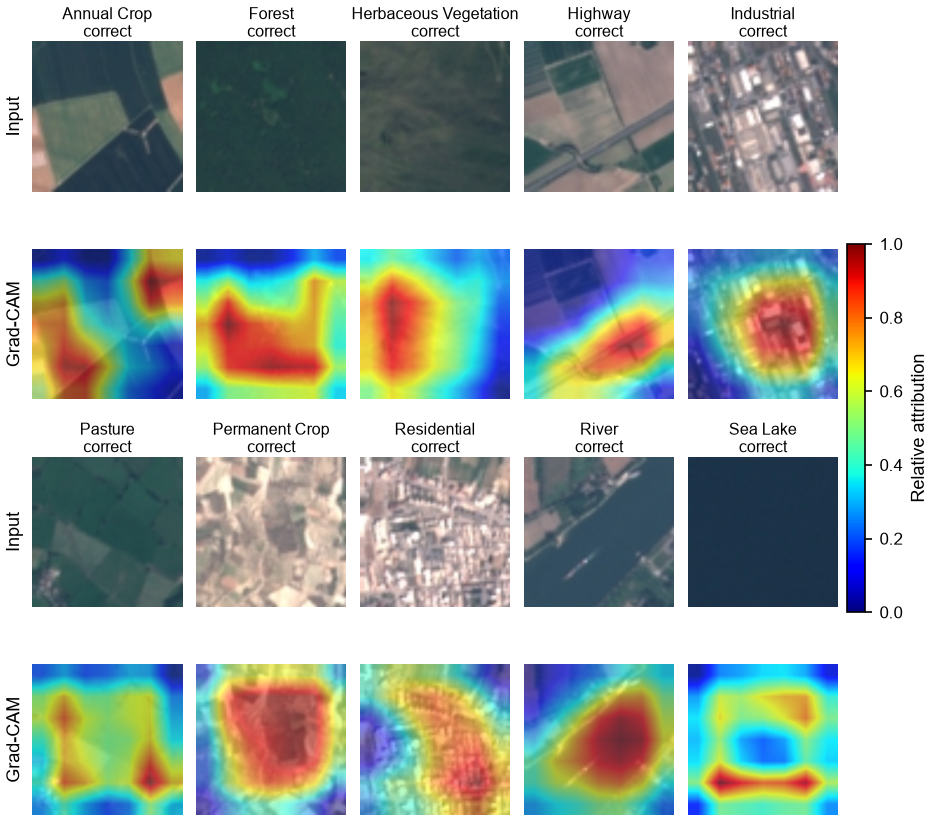

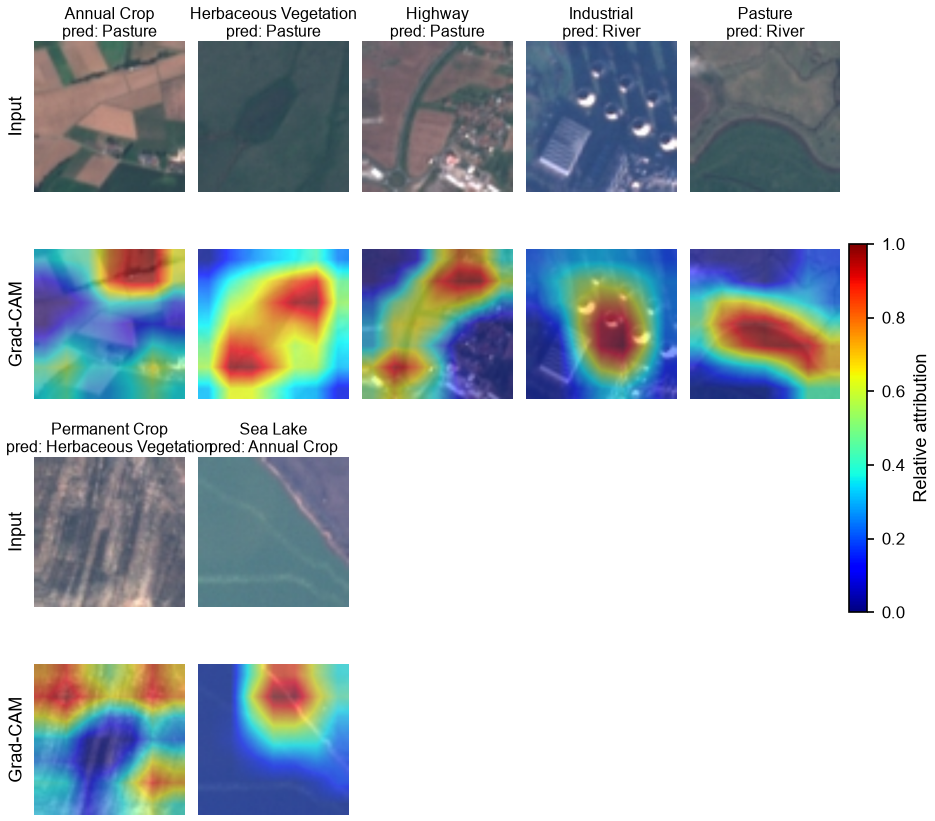

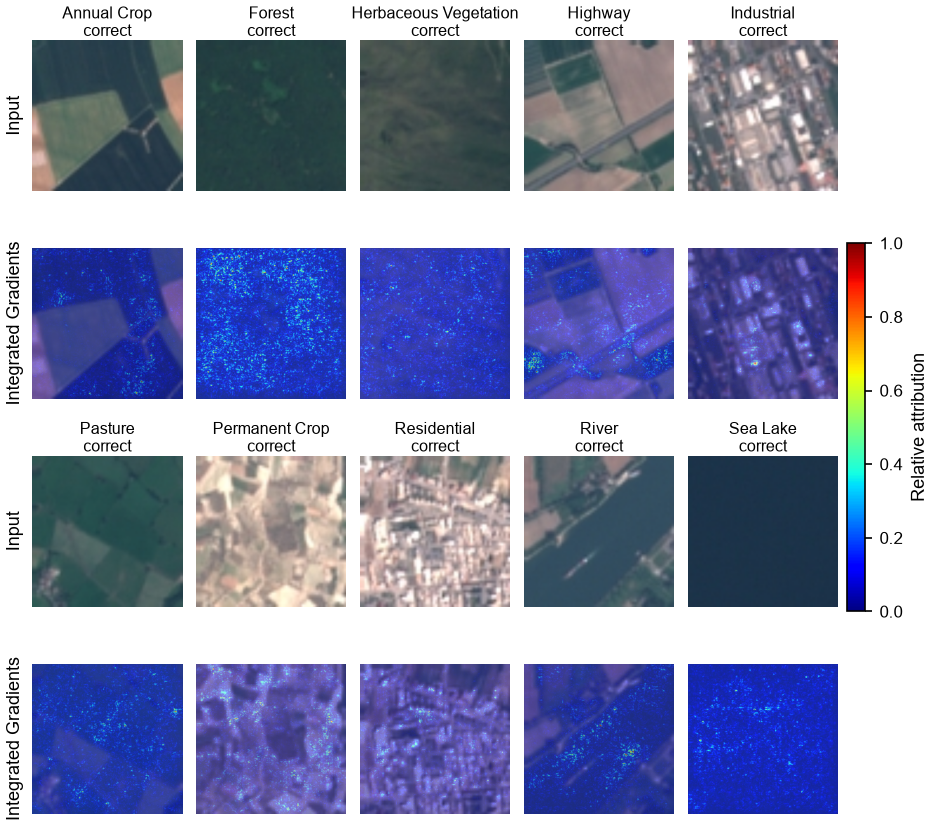

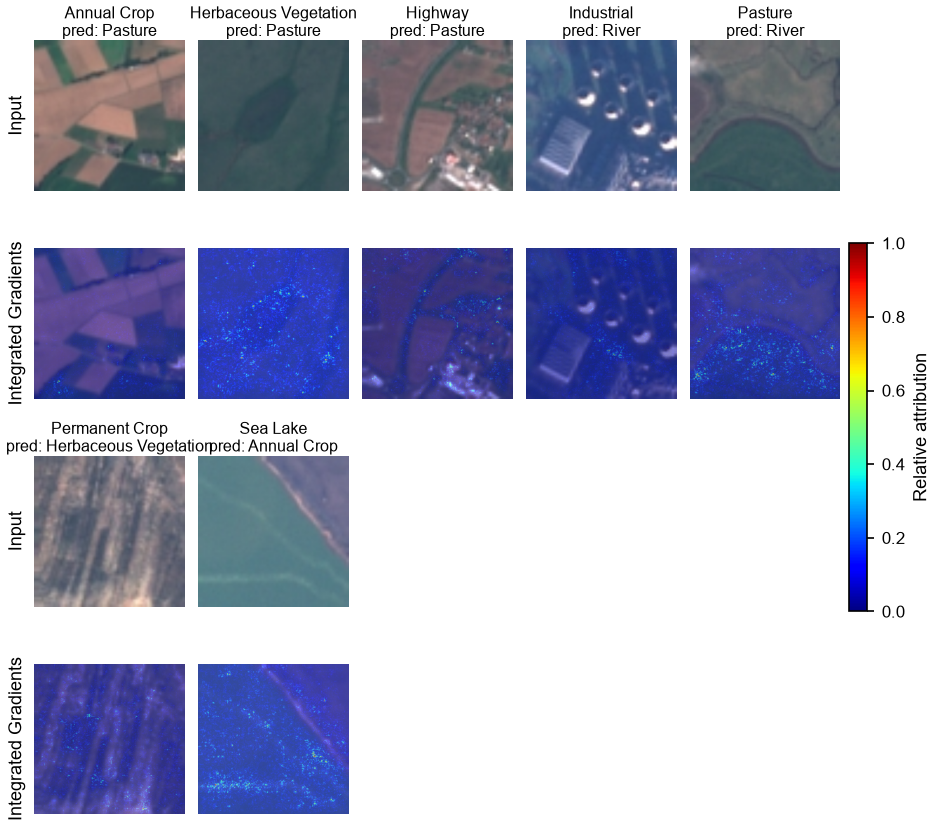

In [15]:
RUN_XAI = RUN_ALL
XAI_MODEL, XAI_SEED, XAI_METHODS = "resnet18", SEED, ["gradcam", "ig"]

if RUN_XAI:
    pred_df = pd.read_csv(OUTPUT_DIR / f"{XAI_MODEL}_seed{XAI_SEED}_test_predictions.csv")
    xai_items = sample_xai_items(pred_df)
    xai_items.to_csv(OUTPUT_DIR / "xai_sample.csv", index=False)
    print("XAI sample:", len(xai_items), "images;", int((xai_items.y_true == xai_items.y_pred).sum()), "correct,",
          int((xai_items.y_true != xai_items.y_pred).sum()), "incorrect")
    xai_model = load_checkpoint(XAI_MODEL, XAI_SEED)
    for method in XAI_METHODS:
        for subset in ("correct", "incorrect"):
            fig = show_xai_examples(xai_model, XAI_MODEL, xai_items, method, subset)
            if fig is None:
                print(f"No {subset} predictions available for {method}.")
                continue
            save_figure(fig, f"xai_{subset}_{XAI_MODEL}_{method}")
            plt.show()

## Stage 6 — Quantitative explanation evaluation

Protocol (fixed before comparison): target = predicted class; 20 steps; zero and blurred baselines; ordering by most-attributed, least-attributed, and random (mean of five draws) **cells**, with ties broken randomly. Pixels are removed in 14 px cells (a 16x16 grid at 224 px) for every order: single-pixel removal in random order inserts salt-and-pepper noise, to which these classifiers are extremely sensitive (Stage 7), so a random pixel order is not a fair reference for spatially smooth attribution maps. Informative attributions should give **lower** deletion AUC and **higher** insertion AUC than random ordering. Deletion/insertion alone does not establish faithfulness, so the stage also reports (i) stability under label-preserving transformations (equivariance-adjusted Spearman correlation) and (ii) a cascading parameter-randomisation sanity check, where correlation with the original map should fall as more layers are randomised.

In [16]:
import torchvision.transforms.functional as TF
from scipy.stats import spearmanr, wilcoxon

_trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

def safe_spearman(a, b):
    """Spearman correlation of two maps; NaN (not a warning) when either map is constant,
    which happens legitimately when a randomised network yields a degenerate attribution."""
    a, b = np.ravel(a), np.ravel(b)
    if a.std() == 0 or b.std() == 0:
        return float("nan")
    return float(spearmanr(a, b).correlation)

def _rank_map(attr, kind, rng):
    """Rank of each pixel in the removal/insertion order (0 = first). Ties are broken randomly."""
    a = np.asarray(attr, dtype=np.float64).ravel()
    perm = rng.permutation(a.size)
    if kind == "random":
        order = perm
    elif kind in ("most", "least"):
        key = -a if kind == "most" else a
        order = perm[np.argsort(key[perm], kind="stable")]
    else:
        raise ValueError(kind)
    rank = np.empty(a.size, dtype=np.int64)
    rank[order] = np.arange(a.size)
    return rank

XAI_CELL = 14        # removal granularity in pixels at model resolution; must divide IMG_SIZE

@torch.no_grad()
def deletion_insertion(model, x, attribution, target, steps=20, baseline="zero", kind="most",
                       seed=SEED, chunk=64, cell=None):
    """Deletion and insertion curves in one vectorised pass.
    Deletion: replace the top-k pixels by the baseline. Insertion: start from the baseline and restore them.
    Returns a DataFrame with the fraction of pixels moved and the target-class probability."""
    model.eval()
    x = x.to(DEVICE)
    H, W = x.shape[-2:]
    assert np.asarray(attribution).size == H * W, "Attribution map must match the input resolution"
    rng = np.random.default_rng(seed)
    cell = XAI_CELL if cell is None else int(cell)
    assert H % cell == 0 and W % cell == 0, f"XAI_CELL={cell} must divide the input size {H}x{W}"
    a = np.asarray(attribution, dtype=np.float64).reshape(H, W)
    if cell > 1:                                         # one score per cell: mean attribution
        a = a.reshape(H // cell, cell, W // cell, cell).mean(axis=(1, 3))
    gh, gw = a.shape
    rank = torch.as_tensor(_rank_map(a, kind, rng), device=DEVICE)
    ks = torch.as_tensor(np.round(np.linspace(0, gh * gw, steps + 1)).astype(np.int64), device=DEVICE)
    masks = (rank.view(1, -1) < ks.view(-1, 1)).view(steps + 1, 1, gh, gw)
    if cell > 1:
        masks = masks.repeat_interleave(cell, dim=2).repeat_interleave(cell, dim=3)
    if baseline == "zero":
        base = torch.zeros_like(x)
    elif baseline == "blur":
        base = TF.gaussian_blur(x, kernel_size=[21, 21], sigma=[8.0, 8.0])
    else:
        base = torch.full_like(x, float(baseline))
    deleted, inserted = torch.where(masks, base, x), torch.where(masks, x, base)

    def prob(t):
        out = [torch.softmax(model(t[i:i + chunk]), 1)[:, int(target)].cpu() for i in range(0, len(t), chunk)]
        return torch.cat(out).numpy()

    return pd.DataFrame({"fraction": ks.cpu().numpy() / (gh * gw),
                         "deletion_prob": prob(deleted), "insertion_prob": prob(inserted)})

def curve_auc(df, col):
    return float(_trapz(df[col].to_numpy(), df["fraction"].to_numpy()))

def faithfulness_table(model, name, items, method, steps=20, baseline="zero", n_random=5, return_curves=False):
    """Per-image deletion/insertion AUCs for most-, least-relevant and random pixel orders.
    With return_curves=True, also returns the per-image curves (random order averaged over n_random draws)."""
    fn = ATTR_METHODS[method]
    rows, curves = [], []
    for r in items.itertuples(index=False):
        _, x = load_input(r.path)
        target = int(r.y_pred)
        attr = fn(model, name, x, target)
        out = dict(path=r.path, y_true=int(r.y_true), y_pred=target, method=method, baseline=baseline)
        for kind in ("most", "least"):
            c = deletion_insertion(model, x, attr, target, steps, baseline, kind)
            out[f"del_auc_{kind}"], out[f"ins_auc_{kind}"] = curve_auc(c, "deletion_prob"), curve_auc(c, "insertion_prob")
            curves.append(c.assign(path=r.path, kind=kind))
        rnd = [deletion_insertion(model, x, attr, target, steps, baseline, "random", seed=SEED + j)
               for j in range(n_random)]
        out["del_auc_random"] = float(np.mean([curve_auc(c, "deletion_prob") for c in rnd]))
        out["ins_auc_random"] = float(np.mean([curve_auc(c, "insertion_prob") for c in rnd]))
        curves.append(pd.concat(rnd).groupby("fraction", as_index=False)[["deletion_prob", "insertion_prob"]]
                      .mean().assign(path=r.path, kind="random"))
        rows.append(out)
    df = pd.DataFrame(rows)
    df["del_gap_vs_random"] = df.del_auc_random - df.del_auc_most      # > 0: informative
    df["ins_gap_vs_random"] = df.ins_auc_most - df.ins_auc_random      # > 0: informative
    if return_curves:
        return df, pd.concat(curves, ignore_index=True)
    return df

def summarise_faithfulness(df):
    res = {"n": int(len(df)),
           "mean_del_auc_most": float(df.del_auc_most.mean()), "mean_del_auc_random": float(df.del_auc_random.mean()),
           "mean_ins_auc_most": float(df.ins_auc_most.mean()), "mean_ins_auc_random": float(df.ins_auc_random.mean()),
           "mean_del_gap": float(df.del_gap_vs_random.mean()), "mean_ins_gap": float(df.ins_gap_vs_random.mean())}
    if len(df) >= 6:
        for key, a, b, alt in (("wilcoxon_del_p", df.del_auc_most, df.del_auc_random, "less"),
                               ("wilcoxon_ins_p", df.ins_auc_most, df.ins_auc_random, "greater")):
            try:
                res[key] = float(wilcoxon(a, b, alternative=alt).pvalue)
            except ValueError:                  # all paired differences are zero
                res[key] = float("nan")
    return res

def stability_table(model, name, items, method, noise_pixel_sigma=0.05):
    """Spearman correlation between the original map and the map of a transformed input mapped back."""
    fn = ATTR_METHODS[method]
    g = torch.Generator().manual_seed(SEED)
    sigma_norm = noise_pixel_sigma / float(np.mean(STD))
    tfs = {"hflip": (lambda x: torch.flip(x, [-1]), lambda a: np.flip(a, -1)),
           "vflip": (lambda x: torch.flip(x, [-2]), lambda a: np.flip(a, -2)),
           "rot90": (lambda x: torch.rot90(x, 1, [-2, -1]), lambda a: np.rot90(a, -1)),
           "gauss_noise": (lambda x: x + sigma_norm * torch.randn(x.shape, generator=g), lambda a: a)}
    rows = []
    for r in items.itertuples(index=False):
        _, x = load_input(r.path)
        target = int(r.y_pred)
        base = fn(model, name, x, target)
        for tname, (fwd, inv) in tfs.items():
            xt = fwd(x)
            with torch.no_grad():
                pred_t = int(model(xt.to(DEVICE)).argmax(1))
            at = np.ascontiguousarray(inv(fn(model, name, xt, target)))
            rows.append(dict(path=r.path, transform=tname, spearman=safe_spearman(base, at),
                             pred_unchanged=pred_t == target))
    return pd.DataFrame(rows)

def randomization_stages(model, name):
    if name == "resnet18":
        return ["fc", "layer4", "layer3", "layer2", "layer1", "conv1"]
    if name == "efficientnet_b0":
        return ["classifier"] + [f"features.{i}" for i in reversed(range(len(model.features)))]
    raise ValueError(name)

def randomization_check(model, name, items, method):
    """Cascading randomisation from the output layer towards the input (Adebayo et al., 2018)."""
    fn = ATTR_METHODS[method]
    rows = []
    for r in items.itertuples(index=False):
        _, x = load_input(r.path)
        target = int(r.y_pred)
        ref = fn(model, name, x, target)
        rnd = copy.deepcopy(model).eval()
        torch.manual_seed(SEED)
        for stage in randomization_stages(model, name):
            for m in rnd.get_submodule(stage).modules():
                if hasattr(m, "reset_parameters"):
                    m.reset_parameters()
            a = fn(rnd, name, x, target)
            rows.append(dict(path=r.path, randomized_up_to=stage, spearman=safe_spearman(ref, a)))
    return pd.DataFrame(rows)

In [17]:
RUN_XAI_EVAL = RUN_ALL
XAI_BASELINES = ["zero", "blur"]    # deletion/insertion depend on the baseline, so conclusions must hold under both
if RUN_XAI_EVAL:
    pred_df = pd.read_csv(OUTPUT_DIR / f"{XAI_MODEL}_seed{XAI_SEED}_test_predictions.csv")
    xai_items = sample_xai_items(pred_df)                                  # same seeded sample as Stage 5
    xai_model = load_checkpoint(XAI_MODEL, XAI_SEED)
    for method in XAI_METHODS:
        faith_summary = {}
        for bl in XAI_BASELINES:
            faith, curves = faithfulness_table(xai_model, XAI_MODEL, xai_items, method, baseline=bl,
                                               return_curves=True)
            faith.to_csv(OUTPUT_DIR / f"xai_faithfulness_{XAI_MODEL}_{method}_{bl}.csv", index=False)
            curves.to_csv(OUTPUT_DIR / f"xai_faith_curves_{XAI_MODEL}_{method}_{bl}.csv", index=False)
            faith_summary[bl] = summarise_faithfulness(faith)
        stab = stability_table(xai_model, XAI_MODEL, xai_items, method)
        stab.to_csv(OUTPUT_DIR / f"xai_stability_{XAI_MODEL}_{method}.csv", index=False)
        rand = randomization_check(xai_model, XAI_MODEL, xai_items, method)
        rand.to_csv(OUTPUT_DIR / f"xai_randomization_{XAI_MODEL}_{method}.csv", index=False)
        RESULTS.setdefault("xai", {})[f"{XAI_MODEL}_{method}"] = {
            "faithfulness": faith_summary,
            "stability_mean_spearman": stab.groupby("transform").spearman.mean().to_dict(),
            "randomization_mean_spearman": rand.groupby("randomized_up_to", sort=False).spearman.mean().to_dict()}
        print(method, json.dumps(RESULTS["xai"][f"{XAI_MODEL}_{method}"], indent=2))

gradcam {
  "faithfulness": {
    "zero": {
      "n": 127,
      "mean_del_auc_most": 0.27989715306295443,
      "mean_del_auc_random": 0.30786392161784554,
      "mean_ins_auc_most": 0.3839419954462964,
      "mean_ins_auc_random": 0.30676329377333883,
      "mean_del_gap": 0.02796676855489106,
      "mean_ins_gap": 0.07717870167295753,
      "wilcoxon_del_p": 0.03519058036620194,
      "wilcoxon_ins_p": 0.0027050185880682608
    },
    "blur": {
      "n": 127,
      "mean_del_auc_most": 0.42690564775717627,
      "mean_del_auc_random": 0.5612896085673345,
      "mean_ins_auc_most": 0.5822985675224174,
      "mean_ins_auc_random": 0.5558761894579805,
      "mean_del_gap": 0.13438396081015844,
      "mean_ins_gap": 0.02642237806443697,
      "wilcoxon_del_p": 9.144011003375577e-16,
      "wilcoxon_ins_p": 0.11634329300485097
    }
  },
  "stability_mean_spearman": {
    "gauss_noise": 0.5078773246953928,
    "hflip": 0.8460972324633275,
    "rot90": 0.793748615402133,
    "vflip": 0.

## Stage 7 — Robustness and statistical validation

Pre-defined label-preserving perturbations are applied to the raw 64×64 test images; prediction changes are tested with exact McNemar tests on identical items, with Holm correction across perturbations. Confidence intervals can be resampled at image level or, as here by default, at the level of duplicate groups. Neither is a spatial bootstrap: without geographic identifiers, intervals must not be described as spatially independent.

In [18]:
from scipy.stats import binomtest
from PIL import ImageFilter, ImageEnhance

def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=2000, seed=SEED, groups=None, alpha=0.05):
    """Percentile bootstrap. With `groups`, whole groups are resampled (cluster bootstrap)."""
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    if groups is not None:
        codes, uniq = pd.factorize(np.asarray(groups))
        members = [np.flatnonzero(codes == g) for g in range(len(uniq))]
    def draw():
        if groups is None:
            return rng.integers(0, len(y_true), len(y_true))
        pick = rng.integers(0, len(members), len(members))
        return np.concatenate([members[k] for k in pick])
    vals = np.array([metric_fn(y_true[i], y_pred[i]) for i in (draw() for _ in range(n_boot))])
    return tuple(float(v) for v in np.quantile(vals, [alpha / 2, 1 - alpha / 2]))

def mcnemar_exact(correct_a, correct_b):
    a, b = np.asarray(correct_a, bool), np.asarray(correct_b, bool)
    n01, n10 = int((a & ~b).sum()), int((~a & b).sum())     # discordant pairs
    p = 1.0 if n01 + n10 == 0 else float(binomtest(min(n01, n10), n01 + n10, 0.5).pvalue)
    return {"a_only_correct": n01, "b_only_correct": n10, "p_value": p}

def holm_adjust(pvals):
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (len(p) - rank) * p[idx])
        adj[idx] = min(1.0, running)
    return adj

def compare_models(y_true, preds):
    """Pairwise exact McNemar on identical test items, Holm-adjusted. preds: {label: predicted-class array}."""
    y_true = np.asarray(y_true)
    rows = []
    for (na, pa), (nb, pb) in itertools.combinations(preds.items(), 2):
        r = mcnemar_exact(np.asarray(pa) == y_true, np.asarray(pb) == y_true)
        rows.append(dict(model_a=na, model_b=nb, **r))
    df = pd.DataFrame(rows)
    if len(df):
        df["p_holm"] = holm_adjust(df.p_value)
    return df

def _gauss_noise(sigma):
    def f(img, idx):
        a = np.asarray(img, dtype=np.float32)
        rng = np.random.default_rng(SEED * 1_000_003 + idx)
        return Image.fromarray(np.clip(a + rng.normal(0, sigma * 255, a.shape), 0, 255).astype(np.uint8))
    return f

def _jpeg(quality):
    def f(img, idx):
        buf = io.BytesIO()
        img.save(buf, "JPEG", quality=quality)
        buf.seek(0)
        return Image.open(buf).convert("RGB")
    return f

PERTURBATIONS = {
    "clean": lambda img, idx: img,
    "gauss_noise_0.005": _gauss_noise(0.005), "gauss_noise_0.01": _gauss_noise(0.01),
    "gauss_noise_0.02": _gauss_noise(0.02), "gauss_noise_0.05": _gauss_noise(0.05),
    "blur_r0.5": lambda img, idx: img.filter(ImageFilter.GaussianBlur(0.5)),
    "blur_r1": lambda img, idx: img.filter(ImageFilter.GaussianBlur(1)),
    "brightness_0.8": lambda img, idx: ImageEnhance.Brightness(img).enhance(0.8),
    "brightness_1.2": lambda img, idx: ImageEnhance.Brightness(img).enhance(1.2),
    "contrast_0.8": lambda img, idx: ImageEnhance.Contrast(img).enhance(0.8),
    "contrast_1.2": lambda img, idx: ImageEnhance.Contrast(img).enhance(1.2),
    "jpeg_q90": _jpeg(90), "jpeg_q75": _jpeg(75), "jpeg_q50": _jpeg(50),
    "rot90": lambda img, idx: img.rotate(90),
    "hflip": lambda img, idx: img.transpose(Image.FLIP_LEFT_RIGHT),
}

def robustness_table(model, frame):
    """Accuracy, macro-F1, prediction-flip rate and paired exact McNemar test against the clean input."""
    preds, y_ref = {}, None
    for pname, fn in PERTURBATIONS.items():
        logits, y, _ = predict_logits(model, make_loader(frame, eval_tfms, pre=fn))
        preds[pname], y_ref = logits.argmax(1), y
    clean = preds["clean"]
    rows = []
    for pname, p in preds.items():
        r = dict(perturbation=pname, accuracy=float(accuracy_score(y_ref, p)),
                 macro_f1=float(f1_score(y_ref, p, average="macro")),
                 flip_rate=float((p != clean).mean()))
        if pname != "clean":
            r["p_mcnemar_vs_clean"] = mcnemar_exact(clean == y_ref, p == y_ref)["p_value"]
        rows.append(r)
    df = pd.DataFrame(rows)
    mask = df.perturbation.ne("clean")
    df.loc[mask, "p_holm"] = holm_adjust(df.loc[mask, "p_mcnemar_vs_clean"])
    df["accuracy_drop_vs_clean"] = df.accuracy.iloc[0] - df.accuracy
    return df

In [19]:
RUN_ROBUSTNESS = RUN_ALL        # needs the test predictions written in Stage 4
CI_METRICS = {"accuracy": accuracy_score, "macro_f1": lambda a, b: f1_score(a, b, average="macro"),
              "mcc": matthews_corrcoef}
ci_rows = []
if RUN_ROBUSTNESS:
    group_of = test_df.set_index("relative_path").duplicate_group
    all_preds, y_test = {}, None
    for name in MODELS:
        for s in SEEDS:
            tag = f"{name}_seed{s}"
            pdf = pd.read_csv(OUTPUT_DIR / f"{tag}_test_predictions.csv")
            y_test = pdf.y_true.to_numpy()
            all_preds[tag] = pdf.y_pred.to_numpy()
            gr = group_of.loc[pdf.path].to_numpy()
            ci = bootstrap_ci(pdf.y_true, pdf.y_pred, lambda a, b: f1_score(a, b, average="macro"), groups=gr)
            RESULTS.setdefault("bootstrap", {})[tag] = {"macro_f1_95ci_group_cluster": ci}
            print(tag, "macro-F1 95% CI (duplicate-group bootstrap):", ci)
            for mname, mfn in CI_METRICS.items():
                est = float(mfn(pdf.y_true.to_numpy(), pdf.y_pred.to_numpy()))
                lo, hi = bootstrap_ci(pdf.y_true, pdf.y_pred, mfn, groups=gr)
                ci_rows.append(dict(model=name, seed=s, metric=mname, estimate=est, ci_low=lo, ci_high=hi))
            rob = robustness_table(load_checkpoint(name, s), test_df)
            rob.to_csv(OUTPUT_DIR / f"{tag}_robustness.csv", index=False)
            display(rob.round(4))
    if len(all_preds) > 1:
        cmp = compare_models(y_test, all_preds)
        cmp.to_csv(OUTPUT_DIR / "model_comparison_mcnemar.csv", index=False)
        display(cmp)
    # paired group-cluster bootstrap of the metric difference between models, per seed (same resampled groups)
    if len(MODELS) > 1:
        gcodes, guniq = pd.factorize(group_of.loc[pd.read_csv(OUTPUT_DIR / f"{MODELS[0]}_seed{SEEDS[0]}_test_predictions.csv").path].to_numpy())
        members = [np.flatnonzero(gcodes == g) for g in range(len(guniq))]
        rng_b = np.random.default_rng(SEED)
        picks = [np.concatenate([members[k] for k in rng_b.integers(0, len(members), len(members))]) for _ in range(2000)]
        for s in SEEDS:
            pa = pd.read_csv(OUTPUT_DIR / f"{MODELS[0]}_seed{s}_test_predictions.csv")
            pb = pd.read_csv(OUTPUT_DIR / f"{MODELS[1]}_seed{s}_test_predictions.csv")
            assert (pa.path.values == pb.path.values).all()
            for mname in ("accuracy", "macro_f1"):
                fn_ = CI_METRICS[mname]
                d = np.array([fn_(pb.y_true.values[i], pb.y_pred.values[i]) - fn_(pa.y_true.values[i], pa.y_pred.values[i])
                              for i in picks])
                obs = fn_(pb.y_true.values, pb.y_pred.values) - fn_(pa.y_true.values, pa.y_pred.values)
                lo, hi = np.quantile(d, [0.025, 0.975])
                ci_rows.append(dict(model=f"{MODELS[1]} minus {MODELS[0]}", seed=s, metric=mname + "_difference",
                                    estimate=float(obs), ci_low=float(lo), ci_high=float(hi)))
    ci_table = pd.DataFrame(ci_rows)
    ci_table.to_csv(OUTPUT_DIR / "table_test_ci.csv", index=False)
    RESULTS["ci_table"] = ci_rows
    display(ci_table.round(4))

resnet18_seed42 macro-F1 95% CI (duplicate-group bootstrap): (0.9869626134012107, 0.993233392212395)


,perturbation,accuracy,macro_f1,flip_rate,p_mcnemar_vs_clean,p_holm,accuracy_drop_vs_clean
0,clean,0.9907,0.9902,0.0000,NaN,NaN,0.0000
1,gauss_noise_0.005,0.9653,0.9668,0.0283,0.0000,0.0000,0.0254
2,gauss_noise_0.01,0.8717,0.8688,0.1231,0.0000,0.0000,0.1190
3,gauss_noise_0.02,0.6006,0.5820,0.3974,0.0000,0.0000,0.3901
4,gauss_noise_0.05,0.1407,0.0730,0.8580,0.0000,0.0000,0.8499
5,blur_r0.5,0.9837,0.9832,0.0122,0.0001,0.0003,0.0070
6,blur_r1,0.4277,0.3910,0.5705,0.0000,0.0000,0.5630
7,brightness_0.8,0.9793,0.9788,0.0158,0.0000,0.0000,0.0114
8,brightness_1.2,0.9834,0.9829,0.0111,0.0000,0.0001,0.0073
9,contrast_0.8,0.9857,0.9853,0.0088,0.0013,0.0053,0.0049


resnet18_seed43 macro-F1 95% CI (duplicate-group bootstrap): (0.986704484621312, 0.9929920047091362)


,perturbation,accuracy,macro_f1,flip_rate,p_mcnemar_vs_clean,p_holm,accuracy_drop_vs_clean
0,clean,0.9904,0.9900,0.0000,NaN,NaN,0.0000
1,gauss_noise_0.005,0.9782,0.9788,0.0163,0.0000,0.0000,0.0122
2,gauss_noise_0.01,0.8548,0.8465,0.1405,0.0000,0.0000,0.1356
3,gauss_noise_0.02,0.5534,0.5331,0.4443,0.0000,0.0000,0.4370
4,gauss_noise_0.05,0.1454,0.0818,0.8538,0.0000,0.0000,0.8450
5,blur_r0.5,0.9774,0.9772,0.0187,0.0000,0.0000,0.0130
6,blur_r1,0.3048,0.2285,0.6947,0.0000,0.0000,0.6856
7,brightness_0.8,0.9769,0.9764,0.0202,0.0000,0.0000,0.0135
8,brightness_1.2,0.9826,0.9822,0.0119,0.0000,0.0000,0.0078
9,contrast_0.8,0.9844,0.9842,0.0114,0.0006,0.0024,0.0060


resnet18_seed44 macro-F1 95% CI (duplicate-group bootstrap): (0.9871820701880047, 0.9933919884548243)


,perturbation,accuracy,macro_f1,flip_rate,p_mcnemar_vs_clean,p_holm,accuracy_drop_vs_clean
0,clean,0.9909,0.9905,0.0000,NaN,NaN,0.0000
1,gauss_noise_0.005,0.9640,0.9655,0.0295,0.0000,0.0000,0.0270
2,gauss_noise_0.01,0.8523,0.8469,0.1436,0.0000,0.0000,0.1387
3,gauss_noise_0.02,0.6045,0.5689,0.3935,0.0000,0.0000,0.3865
4,gauss_noise_0.05,0.2177,0.1753,0.7812,0.0000,0.0000,0.7732
5,blur_r0.5,0.9844,0.9842,0.0127,0.0002,0.0010,0.0065
6,blur_r1,0.4375,0.3896,0.5625,0.0000,0.0000,0.5534
7,brightness_0.8,0.9738,0.9739,0.0236,0.0000,0.0000,0.0171
8,brightness_1.2,0.9832,0.9827,0.0104,0.0000,0.0000,0.0078
9,contrast_0.8,0.9842,0.9839,0.0104,0.0000,0.0002,0.0067


... (4 outputs left out)

efficientnet_b0_seed44 macro-F1 95% CI (duplicate-group bootstrap): (0.9788231566400142, 0.9869716196721838)


,perturbation,accuracy,macro_f1,flip_rate,p_mcnemar_vs_clean,p_holm,accuracy_drop_vs_clean
0,clean,0.9837,0.9830,0.0000,NaN,NaN,0.0000
1,gauss_noise_0.005,0.9225,0.9249,0.0695,0.0000,0.0000,0.0612
2,gauss_noise_0.01,0.8559,0.8582,0.1400,0.0000,0.0000,0.1278
3,gauss_noise_0.02,0.7768,0.7693,0.2216,0.0000,0.0000,0.2068
4,gauss_noise_0.05,0.1257,0.0444,0.8764,0.0000,0.0000,0.8580
5,blur_r0.5,0.9762,0.9757,0.0135,0.0001,0.0003,0.0075
6,blur_r1,0.5316,0.5083,0.4699,0.0000,0.0000,0.4520
7,brightness_0.8,0.9640,0.9645,0.0267,0.0000,0.0000,0.0197
8,brightness_1.2,0.9777,0.9772,0.0140,0.0018,0.0088,0.0060
9,contrast_0.8,0.9780,0.9777,0.0137,0.0026,0.0104,0.0057


,model_a,model_b,a_only_correct,b_only_correct,p_value,p_holm
0,resnet18_seed42,resnet18_seed43,16,15,1.000000,1.000000
1,resnet18_seed42,resnet18_seed44,15,16,1.000000,1.000000
2,resnet18_seed42,efficientnet_b0_seed42,34,18,0.036483,0.391410
3,resnet18_seed42,efficientnet_b0_seed43,29,20,0.252870,1.000000
4,resnet18_seed42,efficientnet_b0_seed44,40,13,0.000269,0.004028
5,resnet18_seed43,resnet18_seed44,13,15,0.850554,1.000000
6,resnet18_seed43,efficientnet_b0_seed42,31,16,0.039986,0.391410
7,resnet18_seed43,efficientnet_b0_seed43,28,20,0.312327,1.000000
8,resnet18_seed43,efficientnet_b0_seed44,39,13,0.000410,0.005324
9,resnet18_seed44,efficientnet_b0_seed42,33,16,0.021294,0.255529


,model,seed,metric,estimate,ci_low,ci_high
0,resnet18,42,accuracy,0.9907,0.9876,0.9935
1,resnet18,42,macro_f1,0.9902,0.9870,0.9932
2,resnet18,42,mcc,0.9896,0.9862,0.9928
3,resnet18,43,accuracy,0.9904,0.9873,0.9933
4,resnet18,43,macro_f1,0.9900,0.9867,0.9930
5,resnet18,43,mcc,0.9893,0.9859,0.9925
6,resnet18,44,accuracy,0.9909,0.9878,0.9938
7,resnet18,44,macro_f1,0.9905,0.9872,0.9934
8,resnet18,44,mcc,0.9899,0.9864,0.9931
9,efficientnet_b0,42,accuracy,0.9865,0.9826,0.9899


## Stage 8 — Reporting and reproducibility

Generate the manuscript figures (600 dpi) and tables, run the automated validity audit, and export dataset/split/model metadata, software versions, hyper-parameters, collected results, and a record of methodological limitations. Report only findings actually obtained. Do not claim geographic generalisation without geographic grouping, or localisation accuracy without region-level ground-truth annotations.

### 8A. Manuscript figures (600 dpi)

Every figure is written to `outputs/figures` as PNG at 600 dpi and as a vector PDF with embedded TrueType fonts, at
single- or double-column width with 8-10 pt type and a colour-blind-safe palette. A failure in one figure is reported
and recorded, and does not stop the remaining figures or the validity audit.

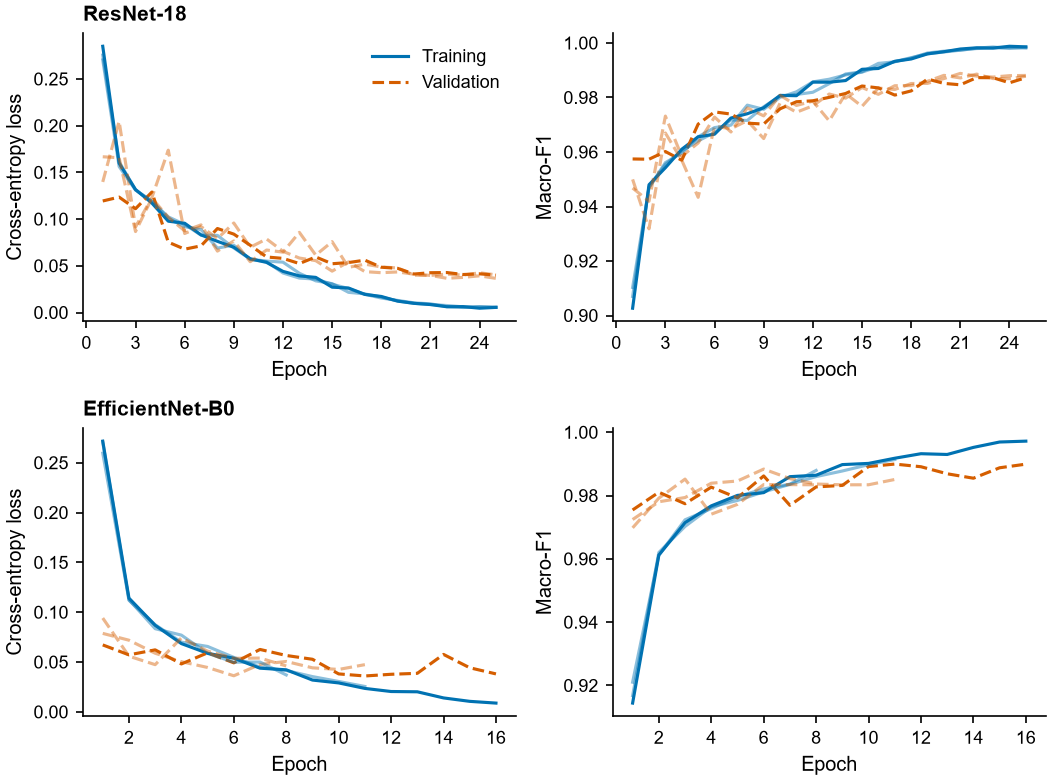

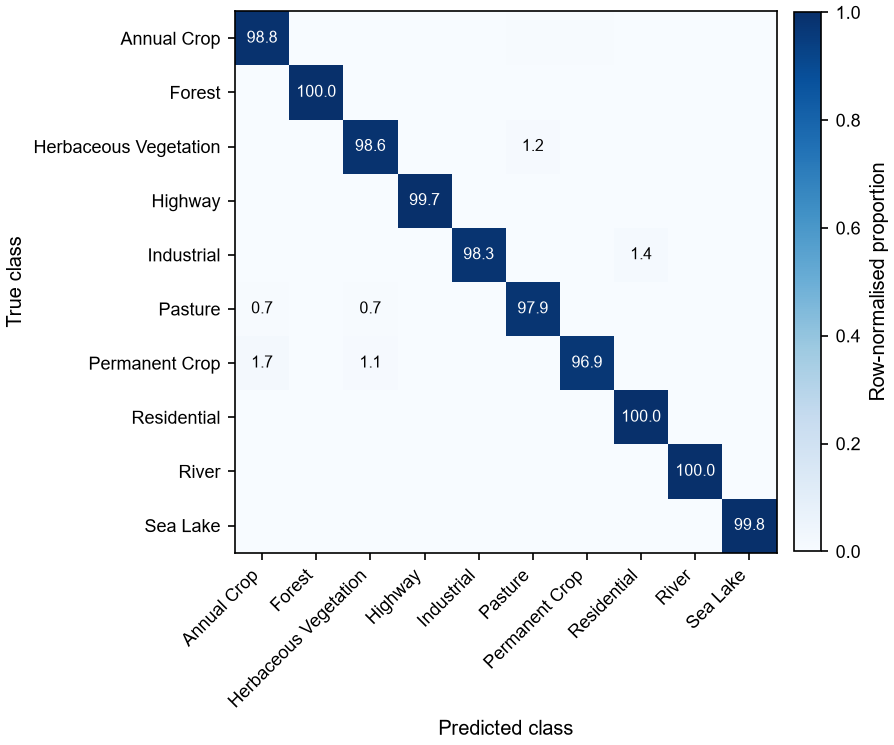

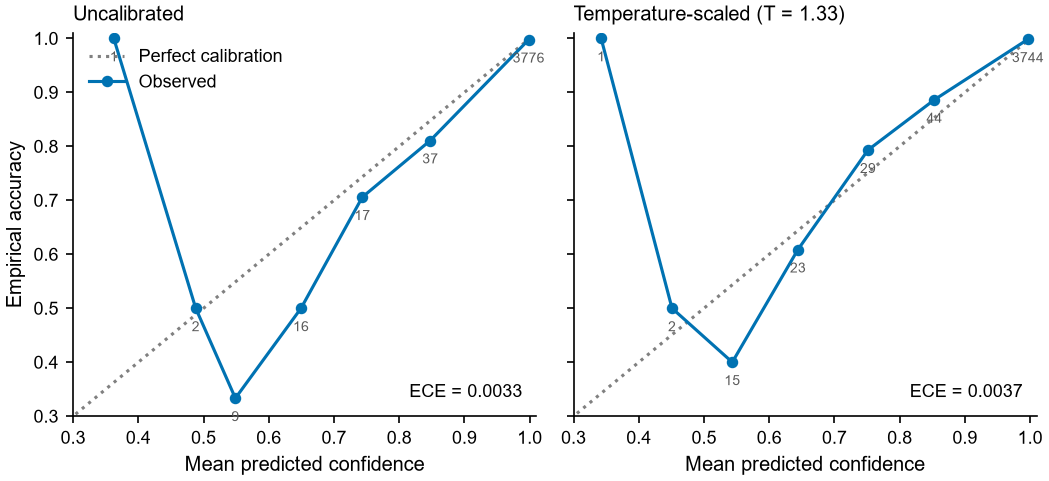

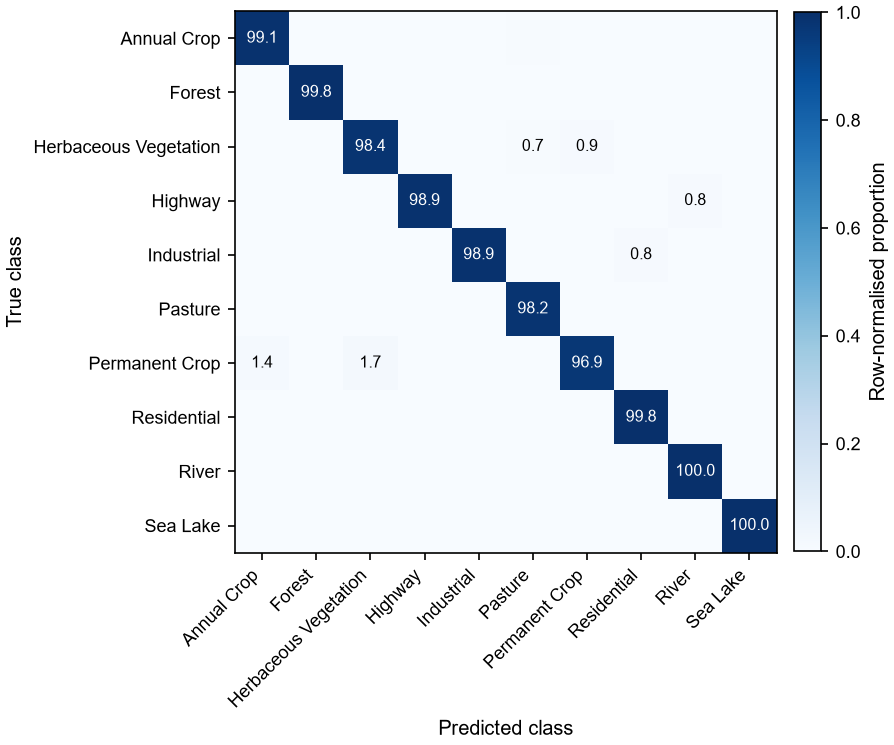

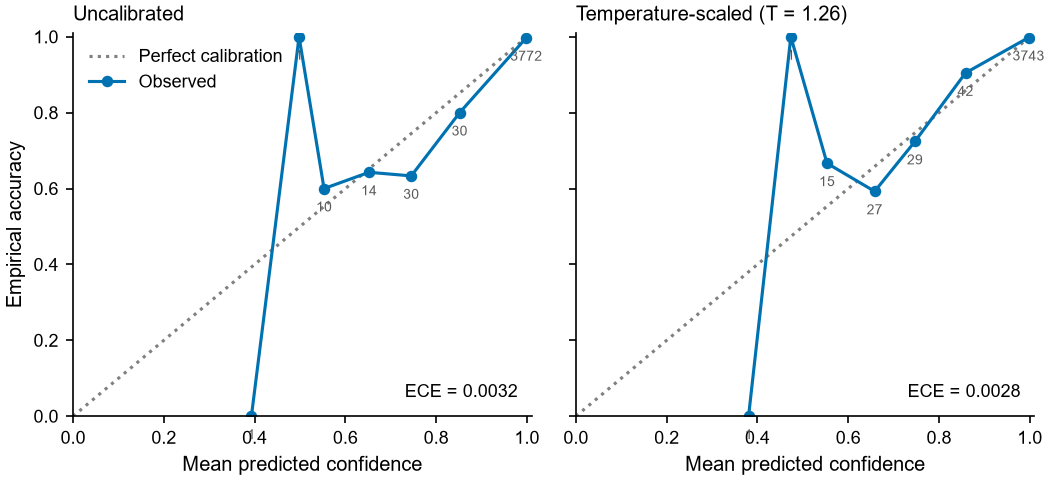

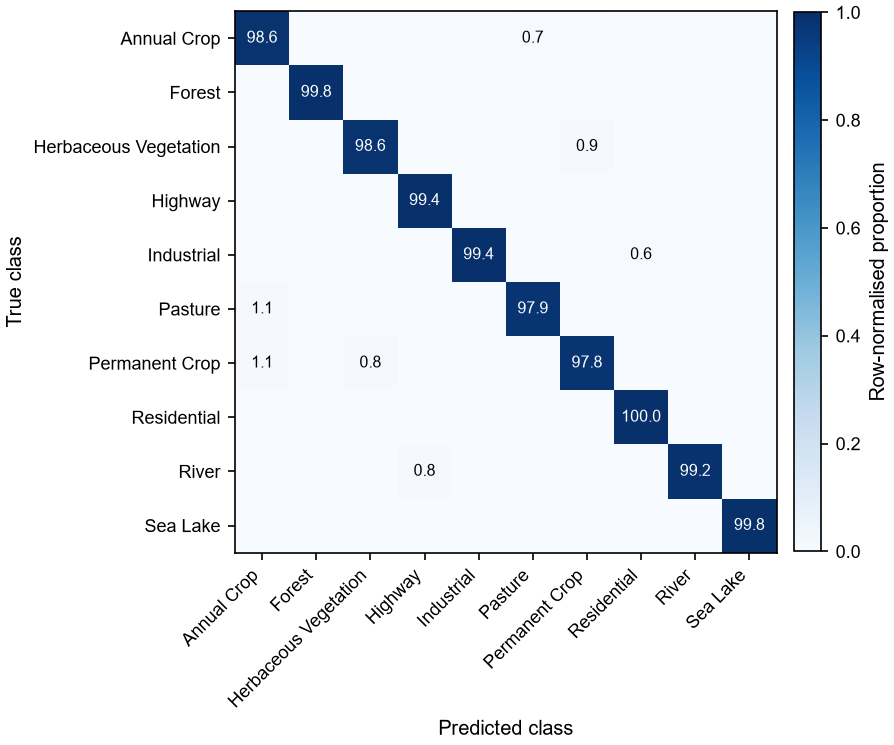

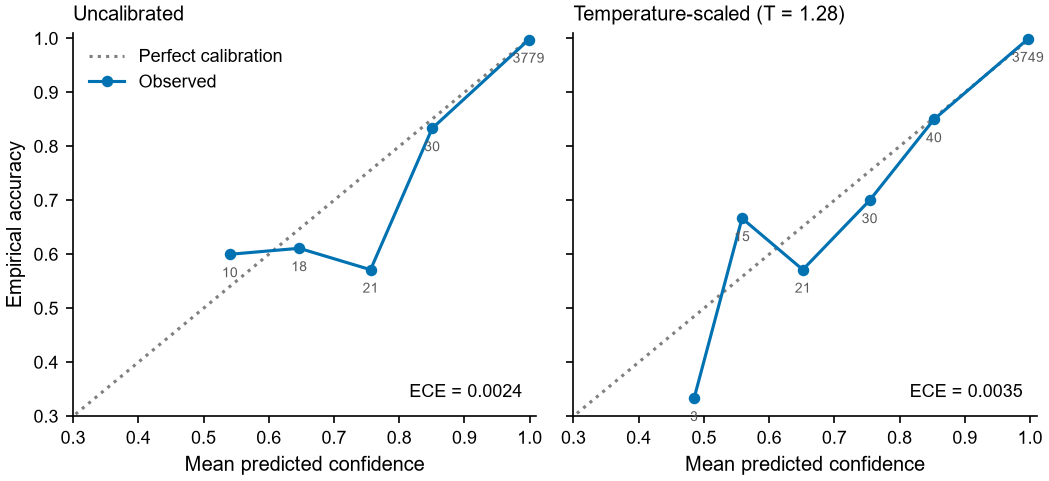

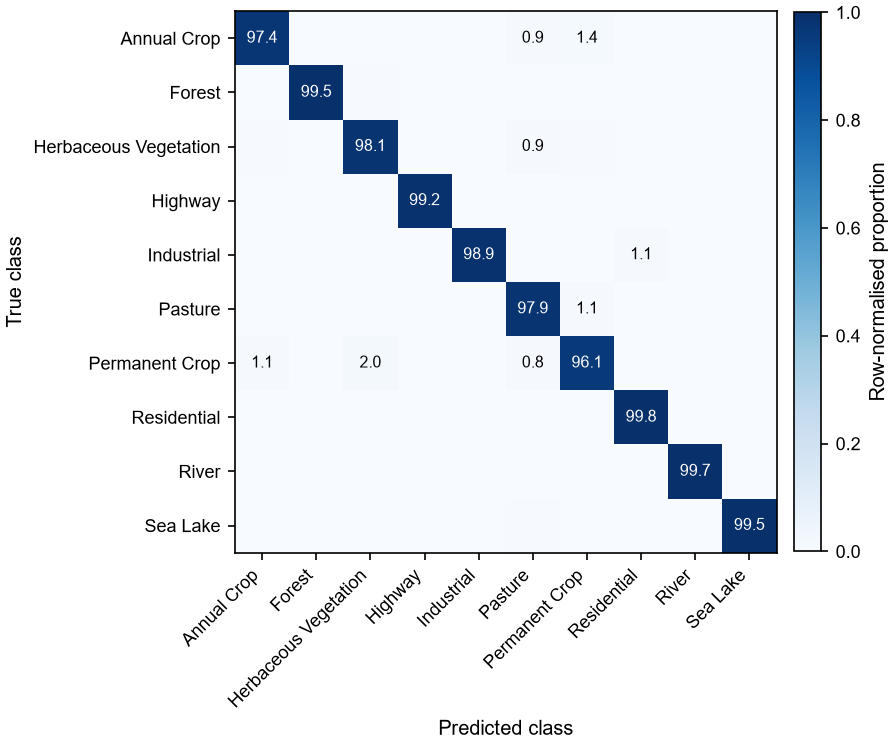

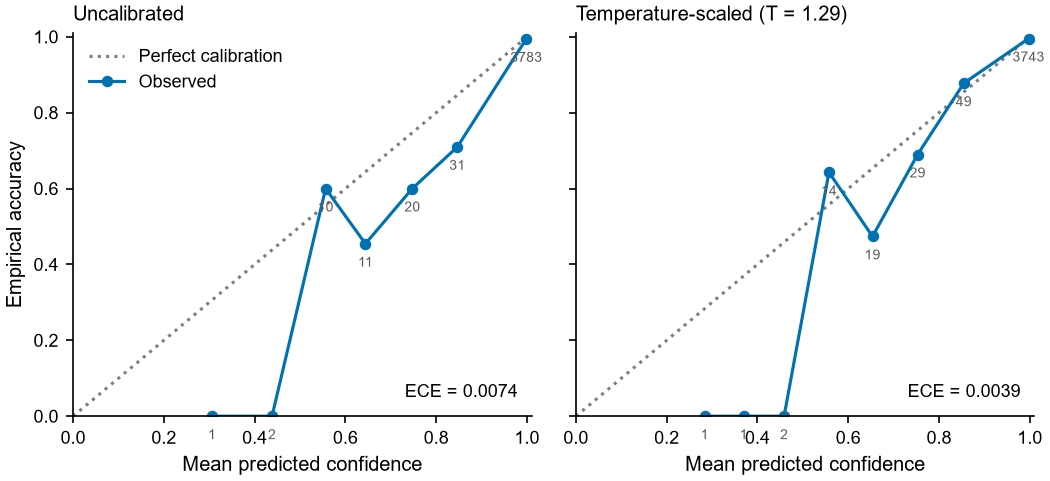

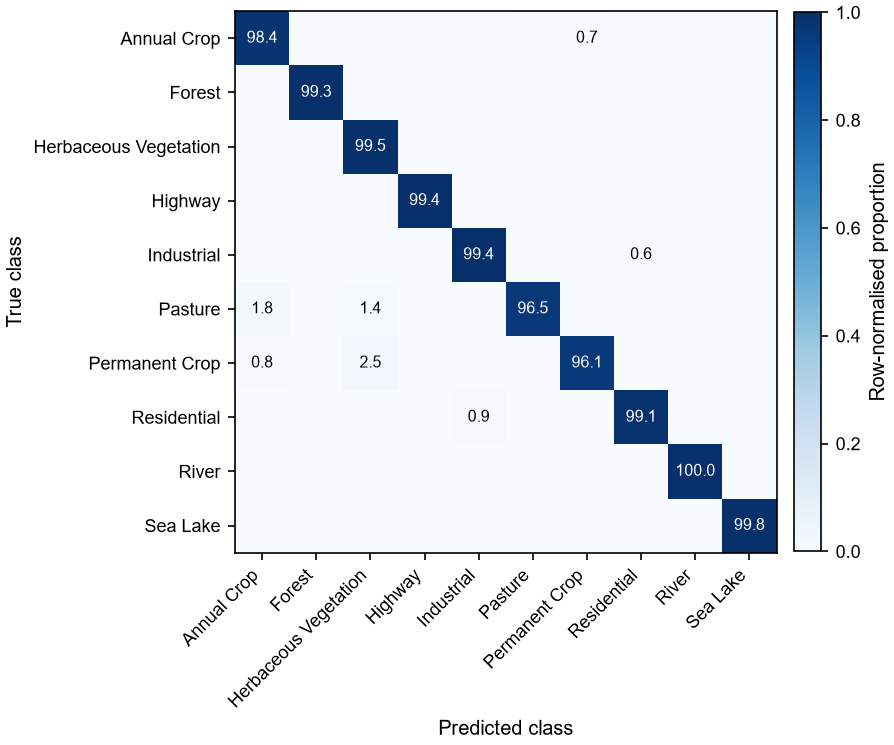

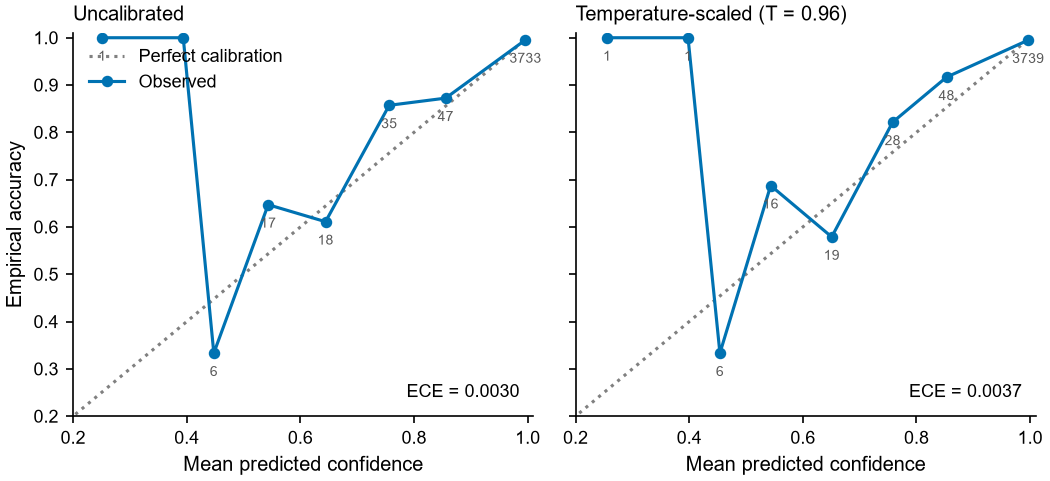

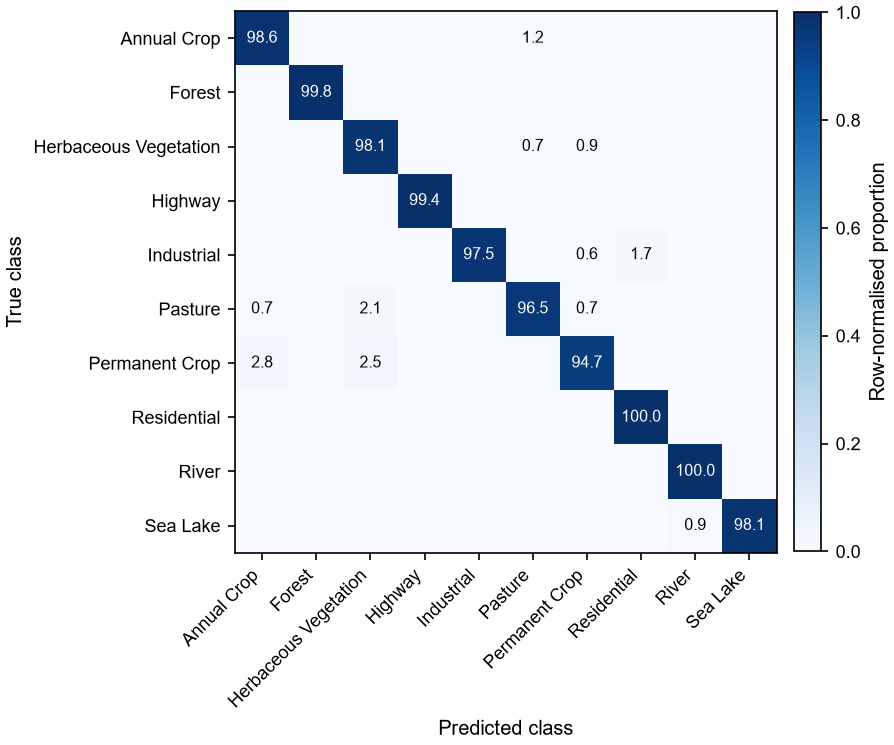

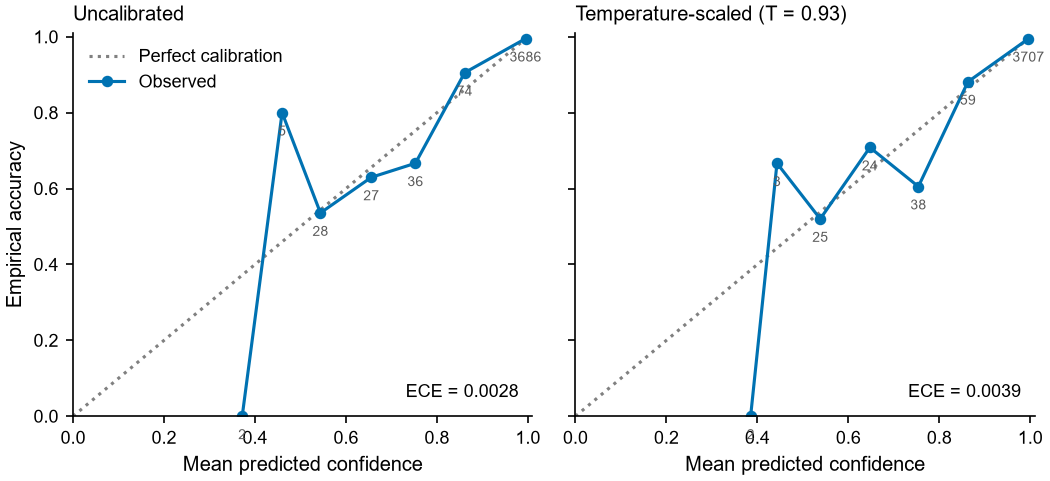

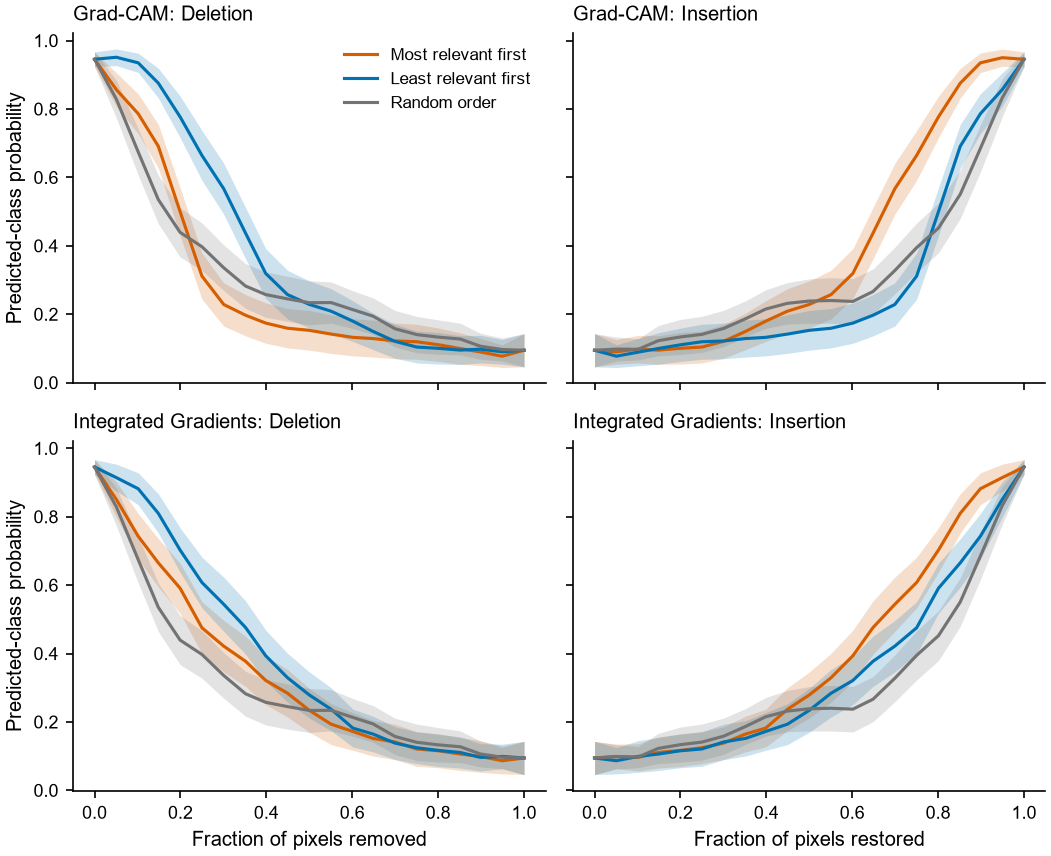

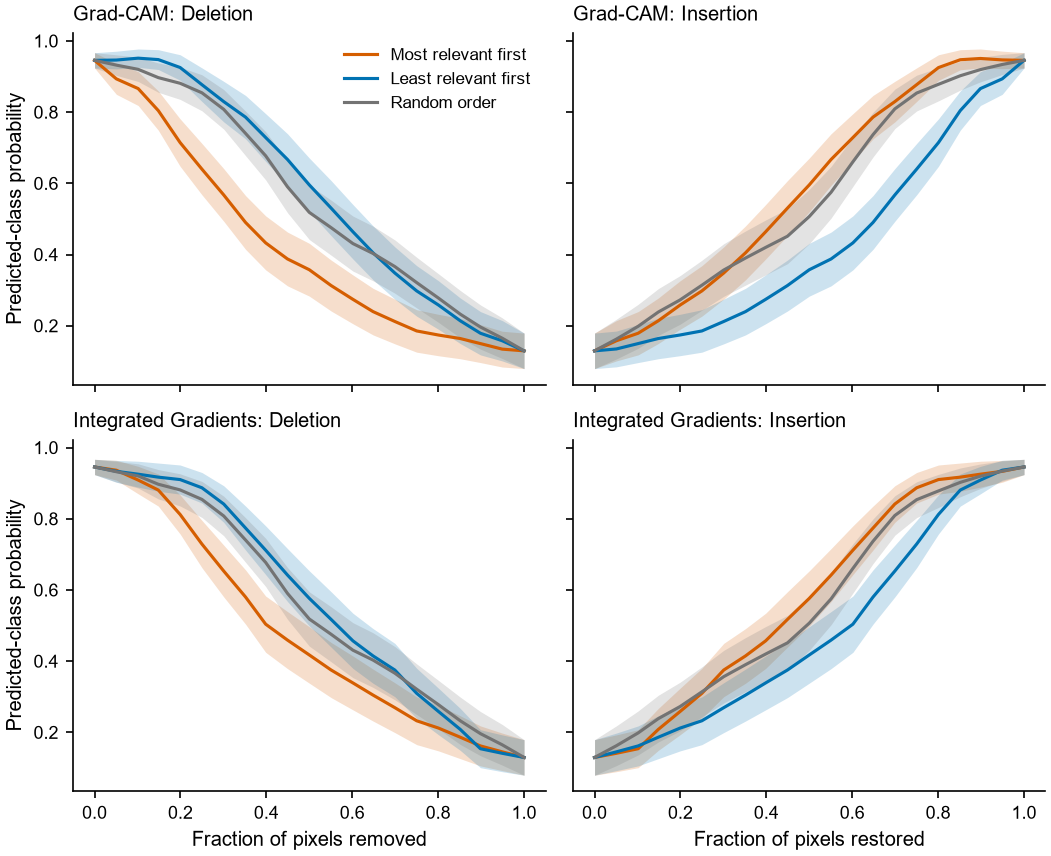

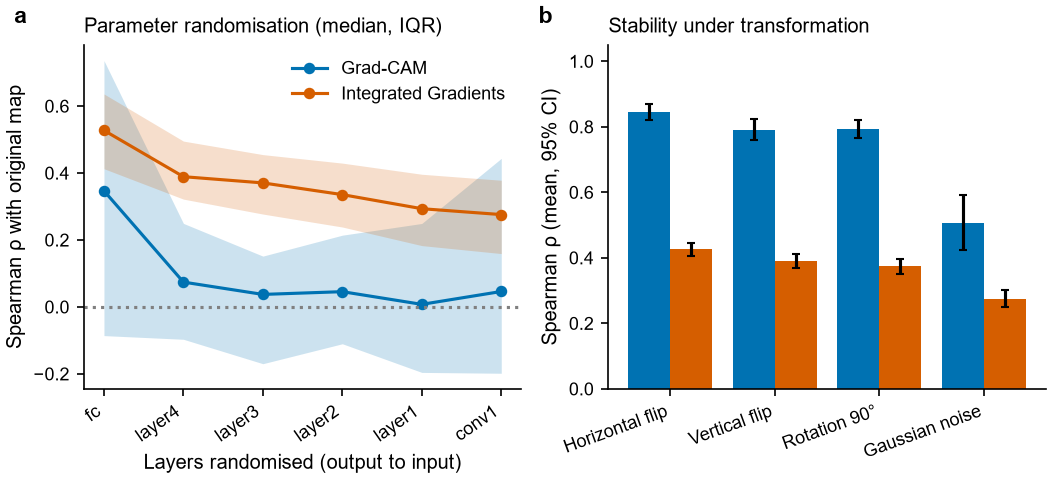

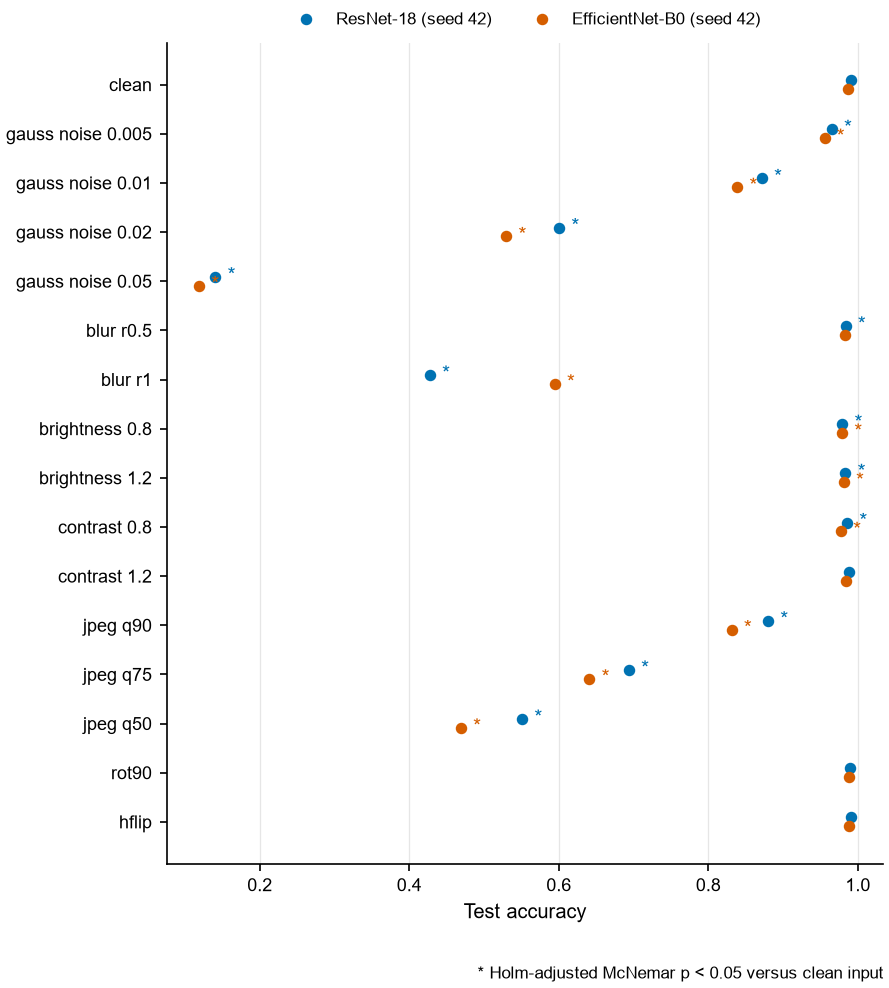

Figures written to C:\Users\DSAI\Desktop\EuroSAT_XAI_Research\outputs\figures
Figure errors: none


In [20]:
RUN_FIGURES = RUN_ALL
figure_errors = {}

def try_fig(label, fn, *args, **kw):
    # Run one figure function; report errors clearly instead of aborting the remaining figures.
    try:
        fig = fn(*args, **kw)
        if fig is not None:
            plt.show()
            plt.close(fig)
    except Exception as e:
        import traceback
        figure_errors[label] = repr(e)
        print(f"FIGURE FAILED: {label}: {e!r}")
        traceback.print_exc()

def _label(ax, text):
    ax.text(-0.16, 1.05, text, transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom")

def fig_training_curves():
    hist = {(m, s): pd.read_csv(OUTPUT_DIR / f"{m}_seed{s}_history.csv") for m in MODELS for s in SEEDS
            if (OUTPUT_DIR / f"{m}_seed{s}_history.csv").exists()}
    fig, axes = plt.subplots(len(MODELS), 2, figsize=(FIG_W2, 2.5 * len(MODELS) + 0.4), squeeze=False)
    for i, m in enumerate(MODELS):
        for j, (col, lab) in enumerate((("loss", "Cross-entropy loss"), ("macro_f1", "Macro-F1"))):
            ax = axes[i, j]
            for k, s_ in enumerate(SEEDS):
                h = hist.get((m, s_))
                if h is None:
                    continue
                ax.plot(h.epoch, h[f"train_{col}"], color=OKABE_ITO[0], ls="-", alpha=1 if k == 0 else 0.45,
                        label="Training" if k == 0 else None)
                ax.plot(h.epoch, h[f"val_{col}"], color=OKABE_ITO[1], ls="--", alpha=1 if k == 0 else 0.45,
                        label="Validation" if k == 0 else None)
            ax.set_xlabel("Epoch")
            ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
            ax.set_ylabel(lab)
            if j == 0:
                ax.set_title(MODEL_LABEL.get(m, m), loc="left", fontweight="bold")
            if i == 0 and j == 0:
                ax.legend(loc="best")
    fig.tight_layout()
    save_figure(fig, "fig_training_curves")
    return fig

def fig_confusion(tag, split="test"):
    cm = pd.read_csv(OUTPUT_DIR / f"{tag}_{split}_confusion_matrix.csv", index_col=0)
    norm = cm.div(cm.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
    fig, ax = plt.subplots(figsize=(FIG_W2 * 0.82, FIG_W2 * 0.72))
    im = ax.imshow(norm.values, cmap="Blues", vmin=0, vmax=1)
    labels = [pretty_class(c) for c in cm.index]
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    for i in range(len(labels)):
        for j in range(len(labels)):
            v = norm.values[i, j]
            if v >= 0.005:
                ax.text(j, i, f"{100 * v:.1f}", ha="center", va="center", fontsize=7.5,
                        color="white" if v > 0.5 else "black")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    for sp in ax.spines.values():
        sp.set_visible(True)
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    cb.set_label("Row-normalised proportion")
    fig.tight_layout()
    save_figure(fig, f"fig_confusion_{tag}_{split}")
    return fig

def fig_reliability(tag):
    pr = pd.read_csv(OUTPUT_DIR / f"{tag}_test_predictions.csv")
    P = pr[[f"p_{c}" for c in CLASS_NAMES]].to_numpy(float)
    T = RESULTS["predictive"][f"{tag}_test"]["temperature"]
    Pc = softmax_np(np.log(np.clip(P, 1e-12, 1.0)) / T)        # softmax(z / T) == softmax(log p / T)
    y = pr.y_true.to_numpy()
    fig, axes = plt.subplots(1, 2, figsize=(FIG_W2, 3.4), sharex=True, sharey=True)
    lows = []
    for ax, (title, probs) in zip(axes, (("Uncalibrated", P), (f"Temperature-scaled (T = {T:.2f})", Pc))):
        conf, hit = probs.max(1), probs.argmax(1) == y
        edges = np.linspace(0, 1, 11)
        xs, ys, ns = [], [], []
        for lo, hi in zip(edges[:-1], edges[1:]):
            m_ = (conf > lo) & (conf <= hi)
            if m_.any():
                xs.append(conf[m_].mean()); ys.append(hit[m_].mean()); ns.append(m_.sum())
        ax.plot([0, 1], [0, 1], color="0.5", ls=":", label="Perfect calibration")
        ax.plot(xs, ys, color=OKABE_ITO[0], marker="o", label="Observed")
        for x_, y_, n_ in zip(xs, ys, ns):
            ax.annotate(f"{n_}", (x_, y_), textcoords="offset points", xytext=(0, -11), ha="center", fontsize=6.5,
                        color="0.35")
        ece = expected_calibration_error(probs, y)
        ax.set_title(title, loc="left", fontsize=9.5)
        ax.text(0.97, 0.05, f"ECE = {ece:.4f}", transform=ax.transAxes, ha="right", fontsize=8.5)
        ax.set_xlabel("Mean predicted confidence")
        lows.append(min(xs + ys))
    lo = max(0.0, np.floor((min(lows) - 0.03) * 20) / 20)          # zoom to the occupied range
    for ax in axes:
        ax.set_xlim(lo, 1.01); ax.set_ylim(lo, 1.01)
    axes[0].set_ylabel("Empirical accuracy")
    axes[0].legend(loc="upper left")
    fig.tight_layout()
    save_figure(fig, f"fig_reliability_{tag}")
    return fig

def fig_faithfulness(model, baseline):
    fig, axes = plt.subplots(len(XAI_METHODS), 2, figsize=(FIG_W2, 2.8 * len(XAI_METHODS) + 0.3),
                             squeeze=False, sharex=True, sharey=True)
    styles = (("most", OKABE_ITO[1], "Most relevant first"), ("least", OKABE_ITO[0], "Least relevant first"),
              ("random", "0.45", "Random order"))
    for i, m in enumerate(XAI_METHODS):
        cv = pd.read_csv(OUTPUT_DIR / f"xai_faith_curves_{model}_{m}_{baseline}.csv")
        for j, (col, ttl) in enumerate((("deletion_prob", "Deletion"), ("insertion_prob", "Insertion"))):
            ax = axes[i, j]
            for kind, colr, lab in styles:
                g = cv[cv.kind == kind].groupby("fraction")[col]
                mean, sem = g.mean(), g.std() / np.sqrt(g.count())
                ax.plot(mean.index, mean.values, color=colr, label=lab)
                ax.fill_between(mean.index, np.clip(mean - 1.96 * sem, 0, 1), np.clip(mean + 1.96 * sem, 0, 1),
                                color=colr, alpha=0.2, lw=0)
            ax.set_title(f"{METHOD_LABEL[m]}: {ttl}", loc="left", fontsize=9.5)
            if i == len(XAI_METHODS) - 1:
                ax.set_xlabel("Fraction of pixels " + ("removed" if j == 0 else "restored"))
            if j == 0:
                ax.set_ylabel("Predicted-class probability")
    axes[0, 0].legend(loc="best", fontsize=8)
    fig.tight_layout()
    save_figure(fig, f"fig_faithfulness_{model}_{baseline}")
    return fig

def fig_xai_sanity(model):
    fig, axes = plt.subplots(1, 2, figsize=(FIG_W2, 3.4))
    for k, m in enumerate(XAI_METHODS):
        rd = pd.read_csv(OUTPUT_DIR / f"xai_randomization_{model}_{m}.csv")
        order = list(dict.fromkeys(rd.randomized_up_to))
        g = rd.groupby("randomized_up_to")["spearman"]
        med = g.median().reindex(order)
        q1, q3 = g.quantile(0.25).reindex(order), g.quantile(0.75).reindex(order)
        axes[0].plot(range(len(order)), med.values, marker="o", color=OKABE_ITO[k], label=METHOD_LABEL[m])
        axes[0].fill_between(range(len(order)), q1.values, q3.values, color=OKABE_ITO[k], alpha=0.2, lw=0)
    axes[0].axhline(0, color="0.5", ls=":")
    axes[0].set_xticks(range(len(order)), order, rotation=35, ha="right")
    axes[0].set_xlabel("Layers randomised (output to input)")
    axes[0].set_ylabel("Spearman ρ with original map")
    axes[0].set_title("Parameter randomisation (median, IQR)", loc="left", fontsize=9.5)
    axes[0].legend(loc="best")
    _label(axes[0], "a")
    width = 0.8 / len(XAI_METHODS)
    for k, m in enumerate(XAI_METHODS):
        st = pd.read_csv(OUTPUT_DIR / f"xai_stability_{model}_{m}.csv")
        order2 = ["hflip", "vflip", "rot90", "gauss_noise"]
        g = st.groupby("transform")["spearman"]
        mean = g.mean().reindex(order2)
        err = (1.96 * g.std() / np.sqrt(g.count())).reindex(order2)
        axes[1].bar(np.arange(len(order2)) + k * width, mean.values, width, yerr=err.values, capsize=2,
                    color=OKABE_ITO[k], label=METHOD_LABEL[m])
    axes[1].set_xticks(np.arange(len(order2)) + width * (len(XAI_METHODS) - 1) / 2,
                       ["Horizontal flip", "Vertical flip", "Rotation 90°", "Gaussian noise"], rotation=20, ha="right")
    axes[1].set_ylabel("Spearman ρ (mean, 95% CI)")
    axes[1].set_ylim(min(0, np.nanmin(axes[1].get_ylim())), 1.05)
    axes[1].set_title("Stability under transformation", loc="left", fontsize=9.5)
    _label(axes[1], "b")
    fig.tight_layout()
    save_figure(fig, f"fig_xai_sanity_{model}")
    return fig

def fig_robustness(tags):
    frames = {t: pd.read_csv(OUTPUT_DIR / f"{t}_robustness.csv") for t in tags}
    perts = list(frames[tags[0]].perturbation)
    fig, ax = plt.subplots(figsize=(FIG_W2 * 0.85, 0.34 * len(perts) + 1.3))
    ypos = np.arange(len(perts))
    for k, t in enumerate(tags):
        df = frames[t].set_index("perturbation").reindex(perts)
        ax.plot(df.accuracy.values, ypos + (k - (len(tags) - 1) / 2) * 0.18, "o", color=OKABE_ITO[k % 8],
                label=t.replace("_seed", " (seed ").replace("resnet18", "ResNet-18")
                       .replace("efficientnet_b0", "EfficientNet-B0") + ")")
        if "p_holm" in df:
            for yy, pv, av in zip(ypos + (k - (len(tags) - 1) / 2) * 0.18, df.p_holm.values, df.accuracy.values):
                if pd.notna(pv) and pv < 0.05:
                    ax.text(av, yy, "  *", va="center", fontsize=10, color=OKABE_ITO[k % 8])
    ax.set_yticks(ypos, [p.replace("_", " ") for p in perts])
    ax.invert_yaxis()
    ax.set_xlabel("Test accuracy")
    ax.grid(axis="x", color="0.9", lw=0.6)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=8)
    ax.text(1.0, -0.14, "* Holm-adjusted McNemar p < 0.05 versus clean input", transform=ax.transAxes,
            ha="right", fontsize=8)
    fig.tight_layout()
    save_figure(fig, "fig_robustness")
    return fig

if RUN_FIGURES:
    primary = f"{MODELS[0]}_seed{SEEDS[0]}"
    try_fig("training_curves", fig_training_curves)
    for m in MODELS:
        for s_ in SEEDS:
            tag = f"{m}_seed{s_}"
            try_fig(f"confusion_{tag}", fig_confusion, tag)
            try_fig(f"reliability_{tag}", fig_reliability, tag)
    for bl in XAI_BASELINES:
        try_fig(f"faithfulness_{bl}", fig_faithfulness, XAI_MODEL, bl)
    try_fig("xai_sanity", fig_xai_sanity, XAI_MODEL)
    try_fig("robustness", fig_robustness, [f"{m}_seed{SEEDS[0]}" for m in MODELS])
    print("Figures written to", FIG_DIR)
    print("Figure errors:", figure_errors or "none")

### 8B. Results tables

Test-set metrics are reported as mean ± SD across training seeds (a single value when only one seed was run), for
raw and temperature-scaled probabilities, and exported as CSV and LaTeX.

In [21]:
def metrics_table(split="test"):
    rows = []
    for m in MODELS:
        recs = [RESULTS["predictive"].get(f"{m}_seed{s_}_{split}") for s_ in SEEDS]
        recs = [r for r in recs if r]
        if not recs:
            continue
        for state in ("raw", "calibrated"):
            row = {"Model": MODEL_LABEL.get(m, m), "Probabilities": state, "Seeds": len(recs)}
            for k in recs[0][state]:
                v = np.array([r[state][k] for r in recs], float)
                row[k] = f"{v.mean():.4f} ± {v.std(ddof=1):.4f}" if len(v) > 1 else f"{v[0]:.4f}"
            rows.append(row)
    return pd.DataFrame(rows)

def to_latex_simple(df):
    cols = list(df.columns)
    lines = ["\\begin{tabular}{" + "l" * len(cols) + "}", "\\hline", " & ".join(cols) + " \\\\", "\\hline"]
    for _, r in df.iterrows():
        lines.append(" & ".join(str(r[c]).replace("±", "$\\pm$").replace("_", "\\_") for c in cols) + " \\\\")
    lines += ["\\hline", "\\end{tabular}"]
    return "\n".join(lines)

if RUN_FIGURES and "predictive" in RESULTS:
    table_test = metrics_table("test")
    table_test.to_csv(OUTPUT_DIR / "table_test_metrics.csv", index=False)
    (OUTPUT_DIR / "table_test_metrics.tex").write_text(to_latex_simple(table_test), encoding="utf-8")
    display(table_test)

,Model,Probabilities,Seeds,accuracy,macro_f1,weighted_f1,balanced_accuracy,mcc,nll,ece
0,ResNet-18,raw,3,0.9907 ± 0.0003,0.9902 ± 0.0003,0.9907 ± 0.0003,0.9901 ± 0.0003,0.9896 ± 0.0003,0.0287 ± 0.0012,0.0030 ± 0.0005
1,ResNet-18,calibrated,3,0.9907 ± 0.0003,0.9902 ± 0.0003,0.9907 ± 0.0003,0.9901 ± 0.0003,0.9896 ± 0.0003,0.0283 ± 0.0010,0.0033 ± 0.0005
2,EfficientNet-B0,raw,3,0.9862 ± 0.0024,0.9856 ± 0.0024,0.9862 ± 0.0024,0.9854 ± 0.0025,0.9846 ± 0.0026,0.0450 ± 0.0054,0.0044 ± 0.0026
3,EfficientNet-B0,calibrated,3,0.9862 ± 0.0024,0.9856 ± 0.0024,0.9862 ± 0.0024,0.9854 ± 0.0025,0.9846 ± 0.0026,0.0435 ± 0.0055,0.0038 ± 0.0001


### 8C. Validity audit

Automated checks of the study's internal validity, written to `validity_audit.csv` and the reproducibility manifest.
`FAIL` means a defect that invalidates a claim and must be fixed; `WARN` means a limitation or weak evidence that must
be disclosed or strengthened; `INFO` records scope that belongs in the manuscript; `NOT RUN` means the evidence does not
exist yet. The numerical thresholds for the explanation checks are conventions, not statistical theorems, and are stated
in each row.

In [22]:
from importlib import metadata as importlib_metadata

def pkg_version(n):
    try:
        return importlib_metadata.version(n)
    except importlib_metadata.PackageNotFoundError:
        return None

EXPECTED_EUROSAT_COUNTS = {"AnnualCrop": 3000, "Forest": 3000, "HerbaceousVegetation": 3000, "Highway": 2500,
                           "Industrial": 2500, "Pasture": 2000, "PermanentCrop": 2500, "Residential": 3000,
                           "River": 2500, "SeaLake": 3000}
MIN_XAI_N, MIN_SEEDS, RANDOMIZATION_RHO_MAX, ALPHA = 100, 3, 0.5, 0.05
audit_rows = []

def check(name, fn):
    try:
        status, detail = fn()
    except Exception as e:
        status, detail = "NOT RUN", f"{type(e).__name__}: {e}"
    audit_rows.append({"check": name, "status": status, "detail": detail})

def c_composition():
    got = manifest.groupby("class_name").size().to_dict()
    diff = {k: (got.get(k, 0), v) for k, v in EXPECTED_EUROSAT_COUNTS.items() if got.get(k, 0) != v}
    extra = sorted(set(got) - set(EXPECTED_EUROSAT_COUNTS))
    if not diff and not extra:
        return "PASS", f"{len(manifest)} images; class counts match the published EuroSAT composition"
    return "WARN", f"differs from published EuroSAT composition (observed, expected): {diff}; unexpected classes: {extra}"

def c_integrity():
    v = integrity
    bad = int((~v.status.eq("valid")).sum())
    ok = v[v.status.eq("valid")]
    off = int(((ok.width != EXPECTED_SIZE) | (ok.height != EXPECTED_SIZE) | ok.image_mode.ne("RGB")).sum())
    return ("PASS" if bad == 0 and off == 0 else "FAIL"), f"{bad} unreadable files; {off} images not 64x64 RGB"

def c_exact_contained():
    split_of = dict(zip(all_df.relative_path, all_df.split))
    split_cnt = 0
    for files in exact_groups["files"]:
        if len({split_of.get(f) for f in files.split(" | ")}) > 1:
            split_cnt += 1
    return ("PASS" if split_cnt == 0 else "FAIL"), f"{len(exact_groups)} exact-duplicate groups; {split_cnt} span more than one partition"

def c_label_conflicts():
    n = int((valid_manifest.groupby("duplicate_group").class_name.nunique() > 1).sum())
    return ("PASS" if n == 0 else "FAIL"), f"{n} duplicate groups carry more than one class label (see stage_2_mixed_label_groups.csv)"

def c_disjoint():
    paths = [set(d.relative_path) for d in parts.values()]
    groups = [set(d.duplicate_group) for d in parts.values()]
    clash = sum(len(a & b) for a, b in itertools.combinations(paths, 2)) + sum(len(a & b) for a, b in itertools.combinations(groups, 2))
    return ("PASS" if clash == 0 else "FAIL"), f"{clash} path/group overlaps between train, validation and test"

def c_stratified():
    share = pd.crosstab(all_df.class_name, all_df.split, normalize="index")
    lo, hi = float(share[["validation", "test"]].min().min()), float(share[["validation", "test"]].max().max())
    ok = lo >= SHARE_TOL[0] and hi <= SHARE_TOL[1]
    return ("PASS" if ok else "WARN"), f"per-class validation/test share ranges {lo:.3f}-{hi:.3f} (tolerance {SHARE_TOL})"

def c_review():
    st = manual_review_status
    if not st["sheet_found"]:
        return "WARN", "no near-duplicate review sheet: only exact duplicates were controlled"
    emb = st.get("embedded_decisions", {})
    if st["undecided"]:
        return "FAIL", f"{st['undecided']} candidate pairs undecided"
    n_pre, n_unc = st.get("prefilled_rows", 0), st.get("uncertain_rows", 0)
    if n_pre and not st.get("author_confirmed"):
        return "WARN", (f"{st['rows']} pairs decided but {n_pre} are an assistant visual pre-fill not yet verified by the "
                        f"author on the original images ({n_unc} uncertain, grouped conservatively); do not report as a completed manual review")
    return "PASS", f"{st['rows']} candidate pairs decided ({n_unc} uncertain, grouped as duplicates); author-verified"

def c_geo():
    return "WARN", ("no geographic/source identifiers: spatial independence between train and test is NOT established; "
                    "accuracy may be optimistic for unseen regions (limit claims accordingly)")

def c_test_isolation():
    bad, n = [], 0
    for m in MODELS:
        for s_ in SEEDS:
            pf = OUTPUT_DIR / f"{m}_seed{s_}_test_predictions.csv"
            ck = ckpt_path(m, s_)
            n += 1
            if not pf.exists():
                raise FileNotFoundError(pf.name)
            if ck.stat().st_mtime >= pf.stat().st_mtime:
                bad.append(f"{m}_seed{s_}")
    return ("PASS" if not bad else "FAIL"), (f"{n} runs: checkpoints and temperature fixed on validation before the single "
                                             f"test evaluation" if not bad else f"checkpoint newer than test predictions: {bad}")

def c_seeds():
    n = len(SEEDS)
    return ("PASS" if n >= MIN_SEEDS else "WARN"), (f"{n} training seed(s); " + ("between-run variability reported"
            if n >= MIN_SEEDS else f"set at least {MIN_SEEDS} seeds to quantify between-run variability"))

def c_model_comparison():
    cmp_ = pd.read_csv(OUTPUT_DIR / "model_comparison_mcnemar.csv")
    sig = int((cmp_.p_holm < ALPHA).sum())
    return "INFO", f"{len(cmp_)} pairwise exact McNemar tests, Holm-adjusted; {sig} with p_holm < {ALPHA}"

def _faith(model_key, bl):
    return RESULTS["xai"][model_key]["faithfulness"][bl]

def c_xai_n():
    ns = {k: v["faithfulness"][XAI_BASELINES[0]]["n"] for k, v in RESULTS["xai"].items()}
    ok = all(n >= MIN_XAI_N for n in ns.values())
    return ("PASS" if ok else "WARN"), f"images explained per method: {ns} (target >= {MIN_XAI_N})"

def c_xai_informative():
    fails = []
    for k in RESULTS["xai"]:
        for bl in XAI_BASELINES:
            f = _faith(k, bl)
            good = (f["mean_del_auc_most"] < f["mean_del_auc_random"] and f["mean_ins_auc_most"] > f["mean_ins_auc_random"]
                    and f.get("wilcoxon_del_p", 1) < ALPHA and f.get("wilcoxon_ins_p", 1) < ALPHA)
            if not good:
                fails.append(f"{k}/{bl}")
    return ("PASS" if not fails else "WARN"), ("all methods beat random pixel order on deletion and insertion (Wilcoxon, "
            f"alpha={ALPHA})" if not fails else f"not distinguishable from random order under: {fails}")

def c_xai_baseline():
    flips = []
    for k in RESULTS["xai"]:
        dirs = {bl: (_faith(k, bl)["mean_del_gap"] > 0, _faith(k, bl)["mean_ins_gap"] > 0) for bl in XAI_BASELINES}
        if len(set(dirs.values())) > 1:
            flips.append(k)
    return ("PASS" if not flips else "WARN"), ("conclusion direction identical under both baselines"
            if not flips else f"direction changes with the baseline for: {flips}")

def c_xai_randomization():
    out, bad = {}, []
    for k in RESULTS["xai"]:
        rz = RESULTS["xai"][k]["randomization_mean_spearman"]
        last = list(rz.values())[-1]
        out[k] = round(last, 3)
        if not (abs(last) <= RANDOMIZATION_RHO_MAX):
            bad.append(k)
    return ("PASS" if not bad else "WARN"), (f"mean rho after full randomisation {out} (threshold |rho| <= {RANDOMIZATION_RHO_MAX})"
            + ("" if not bad else f"; maps insensitive to model parameters: {bad}"))

def c_xai_stability():
    return "INFO", {k: {t: round(v, 3) for t, v in RESULTS["xai"][k]["stability_mean_spearman"].items()} for k in RESULTS["xai"]}

def c_convergence():
    msgs, warn = [], False
    for m in MODELS:
        for s_ in SEEDS:
            h = pd.read_csv(OUTPUT_DIR / f"{m}_seed{s_}_history.csv")
            f1 = h.val_macro_f1.to_numpy()
            best = int(f1.argmax()) + 1
            late = len(f1) - best <= 1 and len(f1) >= 6 and f1[-1] - f1[-6:-3].mean() > 0.003
            warn |= bool(late)
            msgs.append(f"{m}/{s_}: best epoch {best}/{len(f1)}" + (" (still improving)" if late else ""))
    return ("WARN" if warn else "PASS"), "; ".join(msgs) + ("; raise EPOCHS so the comparison is not budget-limited" if warn else "")

def c_robustness_severity():
    out = {}
    for m in MODELS:
        for s_ in SEEDS[:1]:
            r = pd.read_csv(OUTPUT_DIR / f"{m}_seed{s_}_robustness.csv").set_index("perturbation")
            out[m] = {k: round(float(r.accuracy[k]), 3) for k in ("gauss_noise_0.01", "blur_r0.5", "jpeg_q75") if k in r.index}
    return "INFO", f"accuracy under mild pixel-level degradation {out}; report as a robustness limitation of 64 px EuroSAT classifiers"

def c_ci_reported():
    p = OUTPUT_DIR / "table_test_ci.csv"
    return ("PASS" if p.exists() else "WARN"), ("group-cluster bootstrap CIs and paired model differences in table_test_ci.csv"
                                                 if p.exists() else "table_test_ci.csv missing")

def c_ci_scope():
    return "INFO", "confidence intervals are duplicate-group cluster bootstraps over test images, not spatial; report accordingly"

def c_figures():
    pngs = sorted(FIG_DIR.glob("*.png"))
    if not pngs:
        raise FileNotFoundError("no figures found")
    low = []
    for pth in pngs:
        with Image.open(pth) as im:
            dpi = im.info.get("dpi", (0, 0))[0]
        if dpi < FIG_DPI - 1:
            low.append(pth.name)
    if figure_errors:
        return "FAIL", f"figure generation errors: {figure_errors}"
    return ("PASS" if not low else "FAIL"), (f"{len(pngs)} PNG figures at {FIG_DPI} dpi, vector PDFs with embedded fonts"
                                              if not low else f"below {FIG_DPI} dpi: {low}")

def c_reproducibility():
    pk = {p: pkg_version(p) for p in ["torch", "torchvision", "numpy", "pandas", "scikit-learn", "scipy", "grad-cam", "captum"]}
    missing = [k for k, v in pk.items() if v is None]
    return ("PASS" if not missing else "WARN"), ("seeds, hyper-parameters, split hashes and package versions recorded"
            if not missing else f"package versions missing: {missing}")

for name, fn in [("dataset_composition", c_composition), ("image_integrity", c_integrity),
                 ("exact_duplicates_contained", c_exact_contained), ("label_conflicts", c_label_conflicts),
                 ("partition_disjointness", c_disjoint), ("class_stratification", c_stratified),
                 ("near_duplicate_review", c_review), ("geographic_independence", c_geo),
                 ("test_set_isolation", c_test_isolation), ("training_seeds", c_seeds),
                 ("model_comparison_tests", c_model_comparison), ("xai_sample_size", c_xai_n),
                 ("xai_beats_random_order", c_xai_informative), ("xai_baseline_sensitivity", c_xai_baseline),
                 ("xai_parameter_randomisation", c_xai_randomization), ("xai_transformation_stability", c_xai_stability),
                 ("training_convergence", c_convergence), ("robustness_severity", c_robustness_severity),
                 ("confidence_intervals_reported", c_ci_reported), ("confidence_interval_scope", c_ci_scope), ("figures_600dpi", c_figures),
                 ("reproducibility_record", c_reproducibility)]:
    check(name, fn)

validity_df = pd.DataFrame(audit_rows)
validity_df["detail"] = validity_df.detail.astype(str)
validity_df.to_csv(OUTPUT_DIR / "validity_audit.csv", index=False)
with pd.option_context("display.max_colwidth", 170, "display.width", 250):
    display(validity_df)
print(validity_df.status.value_counts().to_dict())
if (validity_df.status == "FAIL").any():
    print("VALIDITY FAILURES present: resolve them before any result is reported.")

,check,status,detail
0,dataset_composition,PASS,27000 images; class counts match the published EuroSAT composition
1,image_integrity,PASS,0 unreadable files; 0 images not 64x64 RGB
2,exact_duplicates_contained,PASS,0 exact-duplicate groups; 0 span more than one partition
3,label_conflicts,PASS,0 duplicate groups carry more than one class label (see stage_2_mixed_label_groups.csv)
4,partition_disjointness,PASS,"0 path/group overlaps between train, validation and test"
5,class_stratification,PASS,"per-class validation/test share ranges 0.142-0.143 (tolerance (0.1, 0.19))"
6,near_duplicate_review,PASS,"142 candidate pairs decided (0 uncertain, grouped as duplicates); author-verified"
7,geographic_independence,WARN,no geographic/source identifiers: spatial independence between train and test is NOT established; accuracy may be optimistic for unseen regions (limit claims accordin...
8,test_set_isolation,PASS,6 runs: checkpoints and temperature fixed on validation before the single test evaluation
9,training_seeds,PASS,3 training seed(s); between-run variability reported


{'PASS': 15, 'INFO': 4, 'WARN': 3}


In [23]:
from importlib import metadata as importlib_metadata

def pkg_version(n):
    try:
        return importlib_metadata.version(n)
    except importlib_metadata.PackageNotFoundError:
        return None

def sha256_of(path):
    return sha256_file(path) if Path(path).exists() else None

split_files = {n: SPLIT_DIR / f"{n}.csv" for n in ("train", "validation", "test")}
repro = {
    "study": "EuroSAT-RGB leakage-controlled classification and quantitative XAI",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "seed": SEED,
    "dataset_root": str(DATASET_DIR),
    "manifest_images": int(len(manifest)),
    "valid_images": int(integrity.status.eq("valid").sum()),
    "exact_duplicate_groups": int(len(exact_groups)),
    "classes": sorted(manifest.class_name.unique()),
    "environment": {
        "python": platform.python_version(), "platform": platform.platform(),
        "device": str(DEVICE),
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "packages": {p: pkg_version(p) for p in
                     ["torch", "torchvision", "numpy", "pandas", "scikit-learn", "scipy", "Pillow",
                      "grad-cam", "captum"]}},
    "hyperparameters": HPARAMS,
    "models": MODELS, "training_seeds": SEEDS,
    "split": {
        "strategy": "StratifiedGroupKFold (7 outer / 6 inner folds); groups = exact SHA-256 duplicates "
                    "plus manually confirmed near-duplicates",
        "counts": {n: int(len(d)) for n, d in parts.items()},
        "n_groups": {n: int(d.duplicate_group.nunique()) for n, d in parts.items()},
        "file_sha256": {n: sha256_of(p) for n, p in split_files.items()}},
    "manual_review": manual_review_status,
    "validity_audit": validity_df.to_dict("records") if "validity_df" in globals() else None,
    "figures": {"dpi": FIG_DPI, "formats": list(FIG_FORMATS),
                "files": sorted(p.name for p in FIG_DIR.glob("*")) if FIG_DIR.exists() else []},
    "geographic_independence_established": False,
    "rgb_only_scope": True,
    "results": RESULTS,
    "limitations": [
        "No geographic/source identifiers were used; spatial independence is not established.",
        "Confidence intervals are image- or duplicate-group-level, not spatial.",
        "Source images are 64x64 px and were resized to 224x224 as a modelling choice.",
        "Deletion/insertion, stability, and randomisation checks do not by themselves prove faithfulness.",
        "Validation metrics are optimistic because validation data drive selection and calibration."],
}
with open(OUTPUT_DIR / "reproducibility_manifest.json", "w", encoding="utf-8") as f:
    json.dump(repro, f, indent=2, default=str)
print(json.dumps(repro, indent=2, default=str)[:4000])

{
  "study": "EuroSAT-RGB leakage-controlled classification and quantitative XAI",
  "created_utc": "2026-11-14T15:36:05.073154+00:00",
  "seed": 42,
  "dataset_root": "D:\\datasets\\EuroSAT-RGB",
  "manifest_images": 27000,
  "valid_images": 27000,
  "exact_duplicate_groups": 0,
  "classes": [
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake"
  ],
  "environment": {
    "python": "3.11.18",
    "platform": "Windows-10-10.0.26200-SP0",
    "device": "cuda",
    "gpu": "NVIDIA GeForce RTX 3060",
    "packages": {
      "torch": "2.14.1+cu126",
      "torchvision": "0.29.1+cu126",
      "numpy": "2.4.6",
      "pandas": "3.1.1",
      "scikit-learn": "1.9.1",
      "scipy": "1.17.1",
      "Pillow": "13.0.0",
      "grad-cam": "1.5.7",
      "captum": "0.9.0"
    }
  },
  "hyperparameters": {
    "batch_size": 32,
    "epochs": 25,
    "lr": 0.0003,
    "weight_dec

## Execution gates and outputs

| Stage | Output / gate |
|---|---|
| 1. Audit | Manifest, integrity report, SHA-256 duplicate report, label-conflict count |
| 2. Leakage/split | Completed review sheet (no undecided rows), metadata assessment, group assignments, train/validation/test CSVs, split verification |
| 3. Models | Validation-selected, seed-tagged checkpoints and training histories (`RUN_TRAINING`) |
| 4. Evaluation | Validation-fitted temperature, locked test metrics, class report, confusion matrix, saved predictions (`RUN_TEST_EVAL`) |
| 5. XAI | Class-balanced attribution maps for Grad-CAM and Integrated Gradients (`RUN_XAI`) |
| 6. XAI evaluation | Deletion/insertion with controls, stability, randomisation sanity checks (`RUN_XAI_EVAL`) |
| 7. Robustness | Perturbation results, group-cluster CIs, exact McNemar with Holm correction (`RUN_ROBUSTNESS`) |
| 8. Reporting | 600-dpi figures and tables, validity audit (`validity_audit.csv`), reproducibility manifest, and evidence-aligned conclusions |

**Run All** executes every stage in order (`RUN_ALL = True` in Stage 0). Set `RUN_ALL = False` to run one stage at a time, then enable each stage's own `RUN_*` flag. Stages 1-2 stop with an explicit error if an integrity or leakage gate is not satisfied.

In [4]:
RUN_XAI = RUN_ALL
XAI_MODEL, XAI_SEED, XAI_METHODS = "resnet18", SEED, ["gradcam", "ig"]

if RUN_XAI:
    pred_df = pd.read_csv(OUTPUT_DIR / f"{XAI_MODEL}_seed{XAI_SEED}_test_predictions.csv")
    xai_items = sample_xai_items(pred_df)
    xai_items.to_csv(OUTPUT_DIR / "xai_sample.csv", index=False)
    print("XAI sample:", len(xai_items), "images;", int((xai_items.y_true == xai_items.y_pred).sum()), "correct,",
          int((xai_items.y_true != xai_items.y_pred).sum()), "incorrect")
    xai_model = load_checkpoint(XAI_MODEL, XAI_SEED)
    for method in XAI_METHODS:
        for subset in ("correct", "incorrect"):
            fig = show_xai_examples(xai_model, XAI_MODEL, xai_items, method, subset)
            if fig is None:
                print(f"No {subset} predictions available for {method}.")
                continue
            save_figure(fig, f"xai_{subset}_{XAI_MODEL}_{method}")
            plt.show()

NameError: name 'RUN_ALL' is not defined